<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/09_Malicious_URL_Detection/QSVM_MaliciousURL_Eze2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM and QCNN for malicious-URL detection: Eze, Chaudhry and Jahankhani (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Lauren Eze, Umair B. Chaudhry and Hamid Jahankhani,
> "Quantum-Enhanced Machine Learning for Cybersecurity: Evaluating Malicious URL Detection",
> *Electronics* 14(9), 1827, 2025. https://doi.org/10.3390/electronics14091827

on the public *Malicious and Benign Webpages* dataset (A. K. Singh, *Data in Brief* 32, 106304, 2020; Mendeley Data,
https://doi.org/10.17632/gdx3pkwp47). The paper publishes no code; everything below is written from its text, with the
software stack it names (Qiskit, qiskit-machine-learning, scikit-learn, TensorFlow).

**What the notebook does.** It downloads the first 100,000 rows of the dataset (without the raw HTML), draws the paper's
stratified 5000-row subset, applies the paper's preprocessing (label encoding, 1st/99th-percentile capping, standardisation,
ANOVA feature selection, random under- and over-sampling, 80:20 split), and trains the paper's four model families:
SVM (linear and RBF, grid search with cross-validation), a small 2-D CNN, a **QSVM** (`ZZFeatureMap` with linear entanglement,
fidelity quantum kernel, used three ways: callable kernel, precomputed kernel matrix, `QSVC`) and a **QCNN** (`ZFeatureMap`,
two quantum convolution and two pooling layers, `EstimatorQNN` + COBYLA). It then re-draws the paper's tables and figures,
puts the paper's numbers next to its own with a verdict per claim, and spends two sections on the question the paper does not
ask: *why does the QSVM reach 100 %?* (short answer: the data nearly separate themselves through two JavaScript-length
columns, and the paper's oversampling order lets test rows appear in the training set).

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned Qiskit versions; if Colab asks to restart the session, restart and run all again. No GPU, no IBM Quantum account, no
Kaggle login is needed. The data are streamed from Mendeley Data (about 65 MB).

**Runtime.** `FAST_MODE = True` (2 seeds, 3-fold CV, 60 COBYLA iterations, one CNN/QCNN seed, no whole-oversampled-set runs): about 7
minutes on the validation machine, a shared 8-thread CPU. `FAST_MODE = False` (5 seeds, 10-fold CV, 200 COBYLA iterations,
2 CNN/QCNN seeds, whole oversampled set included) took about 31 minutes on the same machine. The committed outputs are from the `FAST_MODE = False` (full) run.

**What you get at the end.** The paper's Tables 4-6 and Figs 7-24 recomputed (mean +- std over seeds), a leak-free
re-evaluation, a feature ablation, and a table that says for every claim of the paper whether it is *reproduced*,
*not reached* or *cannot be checked*.

## The paper in one page

**Problem.** Classify a web page as malicious (`bad`) or benign (`good`) from ten pre-computed attributes of its URL, host
and JavaScript. The decision is binary; the paper asks whether quantum models beat their classical counterparts.

**Models compared (all simulated on classical hardware).** SVM (linear and RBF) vs **QSVM**; CNN vs **QCNN**.

**Data.** Singh's *Malicious and Benign Webpages* dataset: 1.2 million training URLs (a further 0.36 M test URLs), columns
`url, url_len, ip_add, geo_loc, tld, who_is, https, js_len, js_obf_len, content, label`; labels checked with Google Safe
Browsing; about 2.3 % of pages are malicious. The paper reduces it to a **stratified subset of 5000 rows**.

**Preprocessing (Section 3.1).** No missing values; label encoding of `url, geo_loc, tld, who_is, https, label`; capping of
`url_len, js_len, js_obf_len` at the 1st and 99th percentile; standardisation; ANOVA `SelectKBest` keeps five features
(`tld, who_is, https, js_len, js_obf_len`); PCA scree plot; **random undersampling (RUS)** and **random oversampling (ROS)**
to balance the classes; 80:20 train/test split; 10-fold cross-validation for the classical models.

**Models.** SVM: `C` in [0.1, 1, 10, 100, 1000], RBF `gamma` in [0.001, 0.0001], grid search. CNN: three 2-D convolutions
(32, 64, 64 filters), ReLU, max-pooling, flatten, two dense layers (relu, softmax), Adam, categorical cross-entropy, 10 epochs,
random search of filters / kernel size / dropout. QSVM: `ZZFeatureMap`, linear entanglement, `FidelityQuantumKernel`, used as an SVC
callable kernel (**QSVM CK**), a precomputed kernel matrix (**QSVM PK**) and in `QSVC` (**QSVC Func**). QCNN: `ZFeatureMap`,
two conv + two pool layers, `EstimatorQNN`, `NeuralNetworkClassifier`, COBYLA, Pauli-Z read-out. Because of run time, the paper
used one ninth of the oversampled data for the linear SVM and one seventeenth for QSVM and QCNN.

**Claims (Tables 4-6, Section 4).**

| Model | UNDER acc. | OVER acc. | Remark |
|---|---|---|---|
| QSVM CK / QSVC Func / QSVM PK | 100.00 | 100.00 | "perfect on every measure" |
| SVM linear | 97.83 | 97.49 | |
| SVM rbf | 93.48 | 99.95 | |
| CNN | 91.30 | 99.90 | |
| QCNN | 84.78 | 85.22 | |

Qualitative claims: QSVM beats SVM; CNN beats QCNN; oversampling gives better results than undersampling; quantum models are
much slower to train and test (Table 6: e.g. 138.6 s for QSVM CK vs 2.7 s for the RBF-SVM on the undersampled data).

## What follows the paper and what had to be chosen

The paper fixes the dataset, the five features, the model families and the grids, but no seeds, no feature scaling for the
quantum models, no QCNN wiring, no COBYLA budget and no data-set size for the QSVM. Choices are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data source | Singh's dataset, 1.2 M URLs, "available from the corresponding author" | Same dataset, public on Mendeley Data; the **first 100,000 rows** of the training CSV are streamed, `content` is dropped on the fly (rows are not sorted by class) |
| Subset | stratified 5000 instances | stratified 5000 instances drawn from the 100,000 rows, a new draw per seed (113 malicious, 4887 benign for seed 42) |
| Positive class | malicious (`bad`), but `LabelEncoder` makes `bad` = 0 | malicious = 1 = positive class everywhere (precision / recall / F1 of the malicious class) |
| Capping, scaling, feature choice | stated, fitting data not stated | **fitted on the training split only**; features fixed to the paper's five (`USE_PAPER_FEATURES`) |
| PCA | scree plot, "100 % variance" | scree plot only (five components of five features are a rotation); not applied to model inputs |
| Resampling order | oversampling / undersampling, then 80:20 split | **both orders**: "paper" (resample, then split) and "clean" (split, then resample only the training part, natural test set) |
| Fractions of the oversampled data | 1/9 linear SVM, 1/17 QSVM and QCNN, rest all | the same (`DATASETS`); classical models are also run on the 1/17 subset for a like-for-like comparison |
| SVM | `C` and `gamma` grids, 10-fold CV | same grids; 10-fold CV in the full run, 3-fold in `FAST_MODE`; libsvm capped at 200,000 iterations (CHOICE) so that `C = 1000` cannot stall |
| CNN | layers as listed, random search, 10 epochs | same layers; random search over filters / kernel / dropout / learning rate with a few trials (first trial = the paper's own settings); batch size 32 (CHOICE); a validation part (20 % of the training rows) is held out for model selection and curves |
| Quantum input scaling | not stated | standardised features -> min-max into `[0, bw*pi]` (fitted on training rows, test clipped) |
| ZZFeatureMap | linear entanglement | linear entanglement, `reps = 2` (Qiskit default; CHOICE) |
| Kernel | `FidelityQuantumKernel` | `FidelityStatevectorKernel` (exact, same numbers; checked against `FidelityQuantumKernel` below, which needs one circuit per pair and is too slow to repeat) |
| Kernel bandwidth, SVC `C` | not mentioned | tuned on a validation part of the training rows only (`BANDWIDTHS`, `QSVM_C_GRID`) |
| QCNN wiring | "two convolutional and two pooling layers" | 5-qubit version of the Qiskit tutorial QCNN: conv(0-4), pool(0,1 -> 2,3), conv(2-4), pool(2 -> 3), `<Z>` on qubit 3; 27 weights |
| QCNN optimiser budget | COBYLA, no iteration count | 200 iterations (60 in `FAST_MODE`); exact Aer estimator |
| Runs | one run, 46 test rows (undersampled) | `N_SEEDS` seeds (5 / 2), mean +- std |
| Hardware | simulators only | simulators only (exact; no shot noise) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib,
# seaborn and tensorflow. The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared
# local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in under 10 minutes. False: the full run (several seeds, 200 COBYLA iterations).

SEED       = 42             # CHOICE: the paper gives no seed
DATA_DIR   = "data"         # where the downloaded rows are cached (relative to the working directory)
LOCAL_FILE = ""             # optional: path of your own copy of Webpages_Classification_train_data.csv (or its .zip)
IBM_TOKEN  = ""             # unused: like the paper, everything runs on exact simulators (no real hardware)

# --- data (paper: 1.2 M training URLs -> a stratified subset of 5000 instances) ---
POOL_ROWS   = 100_000       # CHOICE: first 100,000 rows of the 1.2 M-row CSV are streamed (about 65 MB, 1 minute)
N_SUBSAMPLE = 5000          # paper: stratified subset of 5000 instances
TEST_SIZE   = 0.2           # paper: 80:20 split
PAPER_FEATURES = ["tld", "who_is", "https", "js_len", "js_obf_len"]   # paper: the five ANOVA-selected features
USE_PAPER_FEATURES = True   # CHOICE: use the paper's list; False = re-run SelectKBest(f_classif, k=5) on each training split
N_QUBITS    = len(PAPER_FEATURES)   # one feature per qubit

# --- classical models (paper) ---
C_GRID     = [0.1, 1, 10, 100, 1000]   # paper: C for both SVM kernels
GAMMA_GRID = [0.001, 0.0001]           # paper: gamma for the RBF kernel
CNN_EPOCHS = 10                        # paper: 10 epochs, Adam, categorical cross-entropy

# --- quantum models ---
BANDWIDTHS  = [0.1, 0.25, 0.5, 1.0]    # CHOICE: angle range [0, bw*pi] of the ZZFeatureMap inputs, tuned on a validation split
QSVM_C_GRID = [1.0, 10.0]              # CHOICE: SVC regularisation of the quantum kernel machines, tuned on the same split
# SHOTS is not needed: FidelityStatevectorKernel and the exact Aer estimator have no shot noise (as the paper's simulator runs).

# --- run size ---
if FAST_MODE:
    N_SEEDS, HEAVY_SEEDS = 2, 1        # seeds for cheap models / for CNN and QCNN
    CV_FOLDS = 3                       # paper: 10-fold cross-validation inside the SVM grid search
    CNN_TRIALS = 2                     # paper: random search; number of random configurations tried
    QCNN_MAXITER = 60                  # CHOICE: COBYLA iterations (the paper does not say)
else:
    N_SEEDS, HEAVY_SEEDS = 5, 2
    CV_FOLDS = 10
    CNN_TRIALS = 3
    QCNN_MAXITER = 200
SEEDS = [SEED + i for i in range(N_SEEDS)]
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| heavy-model seeds:", SEEDS[:HEAVY_SEEDS], "| CV folds:", CV_FOLDS,
      "| QCNN iterations:", QCNN_MAXITER)

FAST_MODE = False | seeds: [42, 43, 44, 45, 46] | heavy-model seeds: [42, 43] | CV folds: 10 | QCNN iterations: 200


In [3]:
import os, io, time, zlib, struct, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

import sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map, z_feature_map
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.kernels import FidelityStatevectorKernel, FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC, NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
try:
    from qiskit_aer.primitives import EstimatorV2 as AerEstimator
    HAVE_AER = True
except Exception:
    HAVE_AER = False

import tensorflow as tf
from tensorflow import keras

tf.get_logger().setLevel("ERROR")
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer estimator:", HAVE_AER)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer estimator: True
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | tensorflow 2.21.0


## 1. The dataset

Singh's dataset was crawled with the *MalCrawler* tool; labels were validated with Google Safe Browsing. Each row is one web
page: the URL string and its length (`url`, `url_len`), the IP address and the country it is hosted in (`ip_add`, `geo_loc`),
the top-level domain (`tld`), whether the WHOIS record is complete (`who_is`), whether the page is served over https, the
total length of its JavaScript (`js_len`) and the length of the part of it that is obfuscated (`js_obf_len`), the raw page
(`content`) and the label (`good` / `bad`). The training file is a 758 MB zip; the pages' HTML makes the CSV huge, but we never
need it, so the next cell reads the zip as a stream and keeps only the ten tabular columns of the first 100,000 rows.
If the first source is not reachable (the Mendeley link itself sits behind a Cloudflare check that blocks some scripts, so the
direct storage link is tried first), the next one is used; as a last resort download the zip in your browser and set `LOCAL_FILE`.

In [4]:
# The training CSV of the dataset (1.2 M rows, 758 MB zipped, 12 columns incl. the raw HTML in `content`) is far too big
# to download in a class demo. The zip is a plain deflate stream, so we read it sequentially over HTTP, parse the CSV in
# chunks, drop the `content` column on the fly and stop after POOL_ROWS rows.
# CHOICE: the file is not sorted by class (the first 3000 rows already show the global 2.3 % malicious share), so the
# first rows are a fair stand-in for a random draw from the whole file.
MENDELEY_ID = "gdx3pkwp47"      # Singh (2020), Mendeley Data, doi:10.17632/gdx3pkwp47
S3  = "https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/"
MEN = f"https://data.mendeley.com/public-files/datasets/{MENDELEY_ID}/files/"
SOURCES = [   # tried in this order. The S3 object is where the Mendeley download link redirects to; the Mendeley link
              # itself is behind a Cloudflare check that blocks some non-browser clients, hence S3 first.
    ("Mendeley S3, training file",  S3 + "f7c85056-b236-44eb-a7d7-0250d5ce2c4b"),
    ("Mendeley link, training file", MEN + "3d512887-4eb7-404b-968a-95cc82eec1fb/file_downloaded"),
    ("Mendeley S3, test file (0.36 M rows, same layout)", S3 + "5e49070d-2754-4365-8118-9dd1af2d39ad"),
    ("Mendeley link, test file",     MEN + "f4d79321-4919-4257-8231-7ace082fa732/file_downloaded"),
]
USE_COLS = ["url", "url_len", "ip_add", "geo_loc", "tld", "who_is", "https", "js_len", "js_obf_len", "label"]

class ZipStream(io.RawIOBase):
    # Sequential file-like view of the first member of a remote deflate-compressed .zip.
    def __init__(self, url):
        self.r = requests.get(url, stream=True, timeout=120, headers={"User-Agent": "Mozilla/5.0"})
        self.r.raise_for_status()
        self.it = self.r.iter_content(1 << 20); buf = b""
        while len(buf) < 30:
            buf += next(self.it)
        sig, _, _, comp, _, _, _, _, _, nlen, elen = struct.unpack("<IHHHHHIIIHH", buf[:30])
        if sig != 0x04034B50 or comp != 8:
            raise IOError("not a deflate zip stream (blocked or wrong file?)")
        need = 30 + nlen + elen
        while len(buf) < need:
            buf += next(self.it)
        self.d = zlib.decompressobj(-15); self.pending = self.d.decompress(buf[need:]); self.done = False
        self.bytes_in = len(buf)
    def readable(self):
        return True
    def readinto(self, b):
        while not self.pending and not self.done:
            try:
                c = next(self.it)
            except StopIteration:
                self.done = True; break
            self.bytes_in += len(c); self.pending = self.d.decompress(c)
            self.done = self.d.eof
        n = min(len(b), len(self.pending)); b[:n] = self.pending[:n]; self.pending = self.pending[n:]
        return n
    def close(self):
        try:
            self.r.close()
        finally:
            super().close()

def read_rows(opener, n_rows, chunksize=20_000):
    parts, n = [], 0
    stream = opener()
    try:
        for ch in pd.read_csv(io.BufferedReader(stream, 1 << 20) if isinstance(stream, io.RawIOBase) else stream,
                              usecols=USE_COLS, chunksize=chunksize):
            parts.append(ch); n += len(ch)
            if n >= n_rows:
                break
    finally:
        stream.close()
    return pd.concat(parts, ignore_index=True).iloc[:n_rows]

def load_pool():
    cache = os.path.join(DATA_DIR, f"webpages_pool_{POOL_ROWS}.csv.gz")
    if os.path.exists(cache):
        print("using cached", cache); return pd.read_csv(cache), "cache"
    if LOCAL_FILE:
        import zipfile
        if LOCAL_FILE.lower().endswith(".zip"):
            z = zipfile.ZipFile(LOCAL_FILE); name = [m for m in z.namelist() if m.lower().endswith(".csv")][0]
            df = read_rows(lambda: z.open(name), POOL_ROWS)
        else:
            df = read_rows(lambda: open(LOCAL_FILE, "rb"), POOL_ROWS)
        src = "LOCAL_FILE"
    else:
        df, src, errors = None, None, []
        for name, url in SOURCES:
            try:
                t0 = time.time(); df = read_rows(lambda: ZipStream(url), POOL_ROWS); src = name
                print(f"read {len(df):,} rows from '{name}' in {time.time()-t0:.0f} s"); break
            except Exception as e:
                errors.append((name, repr(e)[:120])); print(f"  source '{name}' failed: {repr(e)[:120]}")
        if df is None:
            raise RuntimeError("No source worked. Download Webpages_Classification_train_data.csv.zip from "
                               "https://data.mendeley.com/datasets/gdx3pkwp47 and set LOCAL_FILE. Errors: " + str(errors))
    df.to_csv(cache, index=False)
    return df, src

t0 = time.time()
pool, POOL_SOURCE = load_pool()
print(f"pool: {pool.shape[0]:,} rows x {pool.shape[1]} columns from {POOL_SOURCE} ({time.time()-t0:.0f} s)")
print("missing values:", int(pool.isna().sum().sum()), "   (paper: none)")
print("labels:", pool["label"].value_counts().to_dict(),
      f"-> {100*(pool['label']=='bad').mean():.2f} % malicious ('bad')   (paper: heavily imbalanced, 'good' is the majority)")
pool.head(5)

using cached data\webpages_pool_100000.csv.gz


pool: 100,000 rows x 10 columns from cache (1 s)
missing values: 0    (paper: none)
labels: {'good': 97749, 'bad': 2251} -> 2.25 % malicious ('bad')   (paper: heavily imbalanced, 'good' is the majority)


,url,url_len,ip_add,geo_loc,tld,who_is,https,js_len,js_obf_len,label
0,http://members.tripod.com/russiastation/,40,42.77.221.155,Taiwan,com,complete,yes,58.0,0.0,good
1,http://www.ddj.com/cpp/184403822,32,3.211.202.180,United States,com,complete,yes,52.5,0.0,good
2,http://www.naef-usa.com/,24,24.232.54.41,Argentina,com,complete,yes,103.5,0.0,good
3,http://www.ff-b2b.de/,21,147.22.38.45,United States,de,incomplete,no,720.0,532.8,bad
4,http://us.imdb.com/title/tt0176269/,35,205.30.239.85,United States,com,complete,yes,46.5,0.0,good


## 2. A first look at the data

Before any model: what do the two classes look like? The paper's descriptive statistics, box plots and correlation heat map
(Section 3.1.2) are re-drawn in the next section; here we look at the three length columns and at the JavaScript features
that the paper counts among its content features. Look at the `js_obf_len` rows in particular - we return
to them in Section 13.

In [5]:
# What does the pool look like per class? (natural class balance, no resampling yet)
pool["is_bad"] = (pool["label"] == "bad").astype(int)
display(pool.groupby("label")[["url_len", "js_len", "js_obf_len"]].describe().T.round(1))
print("\nJavaScript features, malicious vs benign:")
ct = pd.crosstab(pool["js_obf_len"] > 0, pool["label"]); ct.index.name = "js_obf_len > 0"; display(ct)
print(f"benign pages with obfuscated JavaScript : {int(((pool.label=='good') & (pool.js_obf_len>0)).sum())} of {int((pool.label=='good').sum()):,}")
print(f"largest js_len of any benign page        : {pool.loc[pool.label=='good','js_len'].max()}")
print(f"malicious pages with js_len above that   : {100*(pool.loc[pool.label=='bad','js_len']>pool.loc[pool.label=='good','js_len'].max()).mean():.1f} %")
bad_js = pool[(pool.label=="bad") & (pool.js_len>0)]
print(f"obfuscated length / total JS length of malicious pages: max {(bad_js.js_obf_len/bad_js.js_len).max():.2f}, mean {(bad_js.js_obf_len/bad_js.js_len).mean():.2f}")
print("unique ip_add values:", pool.ip_add.nunique(), "of", len(pool), "rows -> an identifier, dropped (CLAUDE: identifier columns are dropped)")

label                bad     good
url_len    count  2251.0  97749.0
           mean     36.7     35.8
           std      15.3     14.2
           min      15.0     13.0
           25%      26.0     26.0
           50%      33.0     32.0
           75%      44.0     42.0
           max     416.0    616.0
js_len     count  2251.0  97749.0
           mean    548.7    109.0
           std     203.1     54.1
           min       0.0      0.0
           25%     427.5     65.5
           50%     564.3    110.5
           75%     706.5    155.0
           max     854.1    199.5
js_obf_len count  2251.0  97749.0
           mean    354.0      0.0
           std     180.1      0.0
           min       0.0      0.0
           25%     255.9      0.0
           50%     357.3      0.0
           75%     473.2      0.0
           max     787.6      0.0


JavaScript features, malicious vs benign:


label,bad,good
js_obf_len > 0,,
False,258,97749
True,1993,0


benign pages with obfuscated JavaScript : 0 of 97,749
largest js_len of any benign page        : 199.5


malicious pages with js_len above that   : 94.2 %
obfuscated length / total JS length of malicious pages: max 0.94, mean 0.63


unique ip_add values: 99999 of 100000 rows -> an identifier, dropped (CLAUDE: identifier columns are dropped)


## 3. The stratified 5000-row subset, label encoding and the paper's EDA figures

The paper cuts the data down to 5000 rows with stratified sampling ("which maintains data integrity"), so the subset keeps the
natural class ratio of about 97.7 % benign / 2.3 % malicious (113 malicious rows for seed 42). The categorical columns are label
encoded; the identifier-like `ip_add` is dropped (it is almost unique per row), but `url` is kept as an encoded integer exactly
as the paper lists it. Note that a label-encoded URL is just an arbitrary number - it carries no information about the string.

sample for seed 42: 5000 rows, 113 malicious (2.26 %)   (paper: 5000 rows)
label encoding of the categorical columns, e.g. who_is: {'complete': 0, 'incomplete': 1} | https: {'no': 0, 'yes': 1}


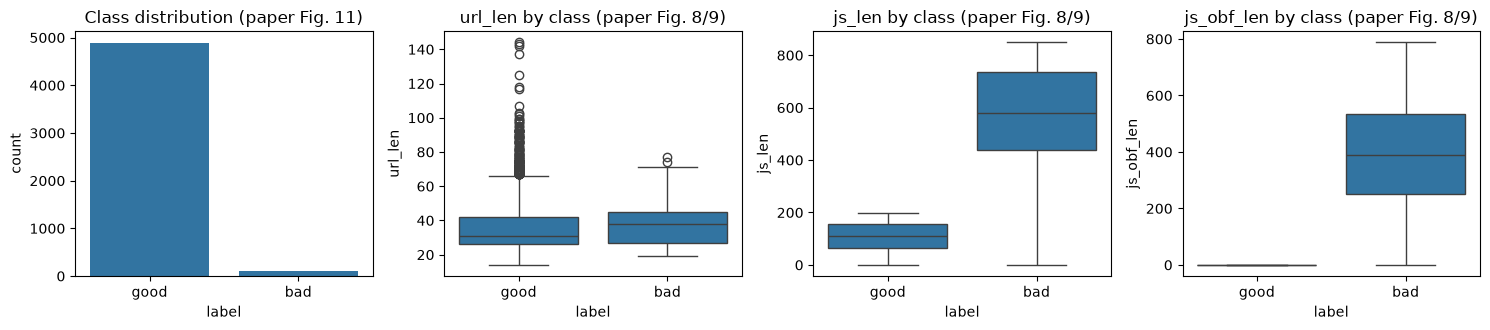

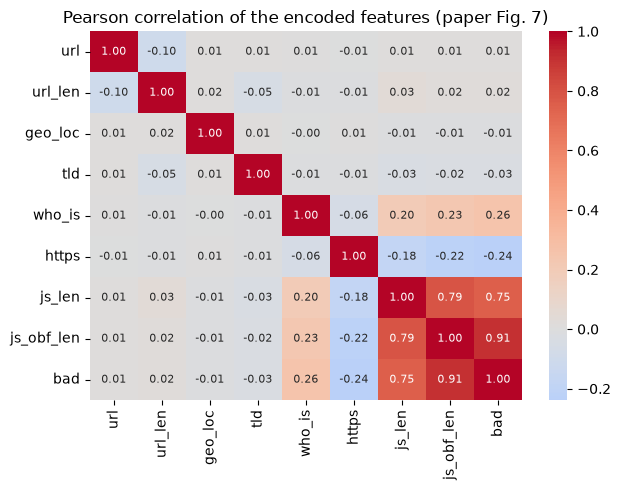

In [6]:
CAT_COLS = ["url", "geo_loc", "tld", "who_is", "https"]            # label-encoded as in the paper (ip_add: identifier, dropped)
NUM_COLS = ["url_len", "js_len", "js_obf_len"]
ALL_COLS = ["url", "url_len", "geo_loc", "tld", "who_is", "https", "js_len", "js_obf_len"]   # the 8 candidate features

def draw_sample(pool, seed):
    # Stratified subset of N_SUBSAMPLE rows (keeps the natural 97.7 / 2.3 % class ratio), then label encoding.
    # LabelEncoder only maps category names to integers (no statistics, no labels), so fitting it on the sample is not leakage.
    s, _ = train_test_split(pool, train_size=N_SUBSAMPLE, stratify=pool["label"], random_state=seed)
    s = s.reset_index(drop=True)
    X = pd.DataFrame({c: LabelEncoder().fit_transform(s[c]) for c in CAT_COLS})
    for c in NUM_COLS:
        X[c] = s[c].astype(float).values
    X = X[ALL_COLS].astype(float)
    y = (s["label"] == "bad").astype(int).values            # CHOICE: malicious ('bad') = 1 = positive class (the paper's LabelEncoder gives bad = 0)
    return X, y, s

X0, y0, sample0 = draw_sample(pool, SEED)
print(f"sample for seed {SEED}: {len(y0)} rows, {y0.sum()} malicious ({100*y0.mean():.2f} %)   (paper: 5000 rows)")
print("label encoding of the categorical columns, e.g. who_is:", dict(zip(sorted(sample0.who_is.unique()), range(2))),
      "| https:", dict(zip(sorted(sample0.https.unique()), range(2))))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
sns.countplot(x=sample0["label"], ax=ax[0]); ax[0].set_title("Class distribution (paper Fig. 11)")
for a, c in zip(ax[1:], NUM_COLS):
    sns.boxplot(x=sample0["label"], y=sample0[c], ax=a); a.set_title(c + " by class (paper Fig. 8/9)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6.5, 5))
sns.heatmap(pd.concat([X0, pd.Series(y0, name="bad")], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Pearson correlation of the encoded features (paper Fig. 7)"); plt.tight_layout(); plt.show()

## 4. Feature selection (ANOVA, PCA) and the preprocessing pipeline

The paper runs an ANOVA F-test (`SelectKBest`) and reports that `tld, who_is, https, js_len, js_obf_len` are the five best features;
a PCA scree plot then shows that these five components carry "100 %" of the variance, which is trivially true for five
components of five variables. The first cell below repeats both on the natural subset (for display only), and finds the same five
features. The second cell defines the preprocessing used by all models: percentile capping, then standardisation (paper), then
- for the quantum models - min-max scaling into the angle range `[0, bw*pi]`. **All of it is fitted on the training rows only.**

,ANOVA F
js_obf_len,23329.9
js_len,6582.8
who_is,351.9
https,303.0
tld,4.3
url_len,2.2
url,0.6
geo_loc,0.6


top five: ['js_obf_len', 'js_len', 'who_is', 'https', 'tld'] | paper: ['tld', 'who_is', 'https', 'js_len', 'js_obf_len'] | same set: True


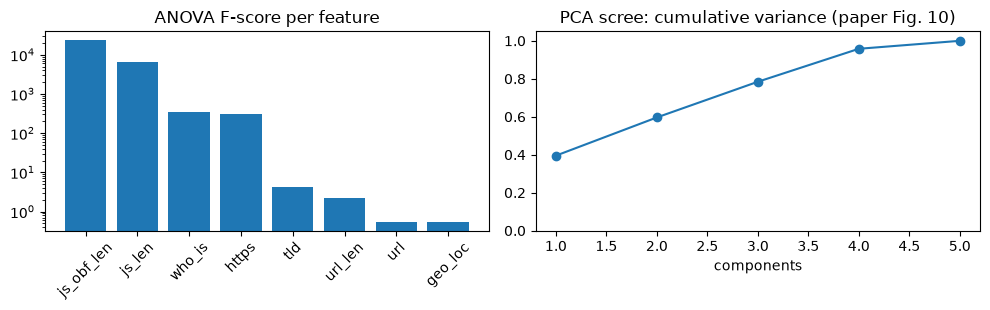

explained variance ratios: [0.395 0.201 0.188 0.174 0.042] -> a 5-component PCA of 5 features is only a rotation, so it is not applied to the model inputs


In [7]:
# Paper: ANOVA F-test (SelectKBest) picks the five best features; a PCA scree plot of them shows that five components
# carry 100 % of the variance. Here both are run once on the natural sample, for display only: no model below uses this
# fit (that would use the test labels). The models use the paper's five features (PAPER_FEATURES) or re-select on each
# training split (USE_PAPER_FEATURES = False).
sk_full = SelectKBest(f_classif, k=5).fit(X0, y0)
scores = pd.Series(sk_full.scores_, index=ALL_COLS).sort_values(ascending=False)
display(scores.round(1).to_frame("ANOVA F"))
print("top five:", list(scores.index[:5]), "| paper:", PAPER_FEATURES, "| same set:", set(scores.index[:5]) == set(PAPER_FEATURES))

Z5 = StandardScaler().fit_transform(X0[PAPER_FEATURES])
ev = PCA(n_components=5, random_state=SEED).fit(Z5).explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(scores.index, scores.values); ax[0].set_yscale("log"); ax[0].set_title("ANOVA F-score per feature"); ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(range(1, 6), np.cumsum(ev), "o-"); ax[1].set_xlabel("components"); ax[1].set_title("PCA scree: cumulative variance (paper Fig. 10)"); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()
print("explained variance ratios:", ev.round(3), "-> a 5-component PCA of 5 features is only a rotation, so it is not applied to the model inputs")

In [8]:
# Every transform below is fitted on the TRAINING split only (CLAUDE rule 6); the test split is only transformed.
CAP_COLS = ["url_len", "js_len", "js_obf_len"]

class Prep:
    # outlier capping (1st / 99th percentile) -> feature choice -> standardisation, all fitted on the training rows
    def __init__(self, features=None, k=5):
        self.features, self.k = features, k
    def _cap(self, X):
        X = X.copy()
        for c, (lo, hi) in self.caps.items():
            X[c] = X[c].clip(lo, hi)
        return X
    def fit(self, X, y):
        self.caps = {c: tuple(np.percentile(X[c], [1, 99])) for c in CAP_COLS if c in X.columns}
        Xc = self._cap(X)
        if self.features is None:
            sel = SelectKBest(f_classif, k=self.k).fit(Xc, y); self.cols = list(Xc.columns[sel.get_support()])
        else:
            self.cols = list(self.features)
        self.ss = StandardScaler().fit(Xc[self.cols])
        return self
    def transform(self, X):
        return self.ss.transform(self._cap(X)[self.cols])

def to_angles(S_tr, S_te, bw=1.0):
    # quantum inputs: min-max scaling of the standardised features into [0, bw*pi], fitted on the training rows, test clipped
    mm = MinMaxScaler((0, np.pi * bw)).fit(S_tr)
    return mm.transform(S_tr), np.clip(mm.transform(S_te), 0, np.pi * bw)

print("Prep and to_angles defined.")

Prep and to_angles defined.


## 5. Random under- and over-sampling, and the order of operations

Only about 2.3 % of the pages are malicious, so the paper balances the classes in two ways and gives both to all models:

* **RUS** keeps all 113 malicious rows and an equally large random set of benign rows (226 rows; 46 test rows with an 80:20 split).
* **ROS** keeps all benign rows and repeats randomly chosen malicious rows until the classes are equal (9774 rows). The paper then
  trains the linear SVM on one ninth and QSVM / QCNN on one seventeenth of this set because of run time.

The paper balances the **whole** subset and splits afterwards. For RUS that is harmless. For ROS it means that a malicious page
that was copied three times can have one copy in the training set and one in the test set: the model is then partly tested on
rows it has already seen. The table below shows how large that overlap is. The notebook therefore also runs a **clean** protocol:
split the natural subset 80:20 first, resample only the training part, and test on the untouched natural test set (about 1000 rows,
23 of them malicious). In that setting plain accuracy is not informative (a model that says "benign" always scores 97.7 %), so the
malicious-class precision, recall and F1 and the balanced accuracy are the numbers to read.

In [9]:
def resample_idx(y, idx, how, rng):
    # random under- / over-sampling of the rows `idx` (positions in the sample); returns positions (oversampling repeats rows)
    bad, good = idx[y[idx] == 1], idx[y[idx] == 0]
    if how == "under":                                       # RUS: drop random benign rows until classes are equal
        out = np.concatenate([bad, rng.choice(good, size=len(bad), replace=False)])
    else:                                                    # ROS: duplicate random malicious rows until classes are equal
        out = np.concatenate([good, bad, rng.choice(bad, size=len(good) - len(bad), replace=True)])
    return rng.permutation(out)

def take_fraction(y, idx, frac, seed):
    if frac >= 1:
        return idx
    keep, _ = train_test_split(idx, train_size=frac, stratify=y[idx], random_state=seed)
    return keep

def build_split(y, regime, frac, protocol, seed):
    # protocol "paper": resample the WHOLE subset, take the fraction, then split 80:20  (the order the paper describes)
    # protocol "clean": split the natural subset first, resample only the training part; the test part keeps the natural ratio
    rs = np.random.default_rng(seed); allidx = np.arange(len(y))
    if protocol == "paper":
        idx = take_fraction(y, resample_idx(y, allidx, regime, rs), frac, seed)
        tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y[idx], random_state=seed)
    else:
        tr0, te = train_test_split(allidx, test_size=TEST_SIZE, stratify=y, random_state=seed)
        tr = take_fraction(y, resample_idx(y, tr0, regime, rs), frac, seed)
    return tr, te

# datasets of the paper: UNDER = undersampled; OVER = oversampled, with the fraction of rows the paper kept for each model:
#   SVM linear 1/9, QSVM and QCNN 1/17, SVM-RBF and CNN the whole oversampled set (Section 5.3 of the paper)
DATASETS = {"UNDER": ("under", 1), "OVER 1/17": ("over", 1 / 17), "OVER full": ("over", 1), "OVER 1/9": ("over", 1 / 9)}

rows = []
for proto in ["paper", "clean"]:
    for dname in DATASETS:
        regime, frac = DATASETS[dname]
        tr, te = build_split(y0, regime, frac, proto, SEED)
        rows.append(dict(protocol=proto, dataset=dname, n_train=len(tr), n_test=len(te),
                         train_malicious=int(y0[tr].sum()), test_malicious=int(y0[te].sum()),
                         distinct_train_rows=len(set(tr)),
                         test_rows_also_in_train_pct=round(100 * np.isin(te, tr).mean(), 1)))
display(pd.DataFrame(rows))
print("paper (UNDER): 46 test instances (ACC steps of 2.2 points). 'test_rows_also_in_train_pct' = share of test rows whose exact row")
print("also sits in the training set: it is 0 for undersampling and large for 'paper'-order oversampling, because the copies are made before the split.")

,protocol,dataset,n_train,n_test,train_malicious,test_malicious,distinct_train_rows,test_rows_also_in_train_pct
0,paper,UNDER,180,46,90,23,180,0.0
1,paper,OVER 1/17,459,115,230,57,331,43.5
2,paper,OVER full,7819,1955,3910,977,4022,50.0
3,paper,OVER 1/9,868,218,434,109,547,50.0
4,clean,UNDER,180,1000,90,23,180,0.0
5,clean,OVER 1/17,460,1000,230,23,314,0.0
6,clean,OVER full,7820,1000,3910,23,4000,0.0
7,clean,OVER 1/9,868,1000,434,23,524,0.0


paper (UNDER): 46 test instances (ACC steps of 2.2 points). 'test_rows_also_in_train_pct' = share of test rows whose exact row
also sits in the training set: it is 0 for undersampling and large for 'paper'-order oversampling, because the copies are made before the split.


## 6. The classical models: SVM, CNN, and two baselines on the quantum inputs

* **SVM** with a linear and an RBF kernel; grid search over the paper's `C` (and RBF `gamma`) values with k-fold cross-validation on the
  training rows. Input: the standardised features.
* **CNN**: the 5 features are reshaped into a 1 x 5 x 1 "image"; three convolutions, max-pooling, flatten, dense layers, Adam, 10 epochs.
  A small random search picks filters, kernel size, dropout and learning rate on a validation part of the training rows.
* **Baselines on the quantum models' own inputs** (the angles in `[0, pi]`): a random forest and a plain RBF-SVC with default
  settings. If a quantum kernel machine only matches these, there is nothing quantum to explain.

In [10]:
def val_split(y, groups, seed, n_splits=5):
    # one stratified 80/20 split of the TRAINING rows in which copies of the same original row stay together (group = row id)
    return next(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups))

def run_svm(kind, ctx):
    grid = {"C": C_GRID} if kind == "linear" else {"C": C_GRID, "gamma": GAMMA_GRID}
    # CHOICE: max_iter caps libsvm at 200,000 iterations so that C = 1000 on overlapping data cannot run for minutes
    gs = GridSearchCV(SVC(kernel=kind, max_iter=200_000, random_state=ctx["seed"]), grid, scoring="accuracy",
                      cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=ctx["seed"]), n_jobs=1)
    t0 = time.perf_counter(); gs.fit(ctx["S_tr"], ctx["ytr"]); t1 = time.perf_counter()
    pred = gs.predict(ctx["S_te"]); t2 = time.perf_counter()
    return [("SVM " + kind if kind == "linear" else "SVM rbf", pred,
             dict(train_s=t1 - t0, test_s=t2 - t1, note=f"{gs.best_params_} cv={gs.best_score_:.3f}"))]

def run_rf(ctx):
    t0 = time.perf_counter(); m = RandomForestClassifier(n_estimators=200, random_state=ctx["seed"], n_jobs=1).fit(ctx["P_tr"], ctx["ytr"]); t1 = time.perf_counter()
    pred = m.predict(ctx["P_te"]); return [("RandomForest (quantum inputs)", pred, dict(train_s=t1 - t0, test_s=time.perf_counter() - t1))]

def run_svc_pi(ctx):
    t0 = time.perf_counter(); m = SVC(kernel="rbf", C=1.0).fit(ctx["P_tr"], ctx["ytr"]); t1 = time.perf_counter()
    pred = m.predict(ctx["P_te"]); return [("SVC rbf (quantum inputs)", pred, dict(train_s=t1 - t0, test_s=time.perf_counter() - t1))]

# --- CNN: three 2-D convolutions over the 1 x 5 "image" of a URL's features, one max-pooling, flatten, two dense layers ---
def build_cnn(n_in, f1=32, k=1, dropout=0.2, lr=1e-3):
    m = keras.Sequential([
        keras.layers.Input((1, n_in, 1)),
        keras.layers.Conv2D(f1, (1, k), padding="same", activation="relu"),     # paper: first layer 32 filters, kernel (1,1)
        keras.layers.Conv2D(64, (1, k), padding="same", activation="relu"),     # paper: next two layers 64 filters
        keras.layers.Conv2D(64, (1, k), padding="same", activation="relu"),
        keras.layers.MaxPooling2D((1, 2)),
        keras.layers.Flatten(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(2, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="categorical_crossentropy", metrics=["accuracy"])
    return m

def run_cnn(ctx):
    seed = ctx["seed"]; keras.utils.set_random_seed(seed)
    X = ctx["S_tr"].reshape(-1, 1, ctx["S_tr"].shape[1], 1); Y = keras.utils.to_categorical(ctx["ytr"], 2)
    itr, iva = val_split(ctx["ytr"], ctx["groups"], seed)
    rs = np.random.default_rng(seed); best = None
    bs = 16 if len(itr) < 1000 else 128          # CHOICE: batch size (not in the paper): small for the 200-500-row sets, larger for the 7800-row set
    t0 = time.perf_counter()
    # CHOICE: the paper's random search (filters, kernel size, dropout; 10 epochs) on a validation part of the training rows;
    # CNN_TRIALS random configurations, the first one is the paper's own layer sizes (32 filters, kernel 1)
    for trial in range(CNN_TRIALS):
        cfg = dict(f1=32, k=1, dropout=0.2, lr=3e-3) if trial == 0 else dict(
            f1=int(rs.choice([16, 32, 64])), k=int(rs.choice([1, 2, 3])), dropout=float(rs.choice([0.0, 0.2, 0.4])), lr=float(rs.choice([1e-3, 3e-3])))
        m = build_cnn(X.shape[2], **cfg); m.fit(X[itr], Y[itr], epochs=CNN_EPOCHS, batch_size=bs, verbose=0)
        va = m.evaluate(X[iva], Y[iva], verbose=0)[1]
        if best is None or va > best[0]:
            best = (va, cfg)
    final = build_cnn(X.shape[2], **best[1])      # final model: trained on the 80 % part, the 20 % part gives the validation curves (paper Fig. 19)
    hist = final.fit(X[itr], Y[itr], epochs=CNN_EPOCHS, batch_size=bs, validation_data=(X[iva], Y[iva]), verbose=0)
    t1 = time.perf_counter()
    pred = final.predict(ctx["S_te"].reshape(-1, 1, ctx["S_te"].shape[1], 1), verbose=0).argmax(1); t2 = time.perf_counter()
    return [("CNN", pred, dict(train_s=t1 - t0, test_s=t2 - t1, note=str(best[1]), history=hist.history))]

print("classical models defined")

classical models defined


## 7. The quantum kernel machine (QSVM)

A quantum feature map `Phi(x)` writes the five numbers of a page into the angles of a 5-qubit circuit. `ZZFeatureMap` applies
Hadamards, single-qubit phase rotations by the feature values and entangling `ZZ` phases between neighbouring qubits
(`entanglement="linear"`), repeated twice. The **fidelity kernel** is the squared overlap of two such states,
`K(a, b) = |<Phi(a)|Phi(b)>|^2` (paper Eq. 9). A classical SVM then does the learning with this kernel. The paper uses the kernel in three
ways: as a callable inside `SVC` (QSVM CK), as a precomputed Gram matrix (QSVM PK) and inside `QSVC` (QSVC Func). All three
are the same optimisation problem with the same kernel, so they must return the same predictions; we check that later.

The cells below draw the feature map, verify our own kernel against the two Qiskit kernel classes, and define the three
variants. The bandwidth `bw` (the angle range `[0, bw*pi]`) is the one free quantum hyper-parameter; it is tuned on a validation part of the
training rows, together with the SVC's `C`.

ZZFeatureMap on 5 qubits: 5 input parameters, depth after decomposition 22


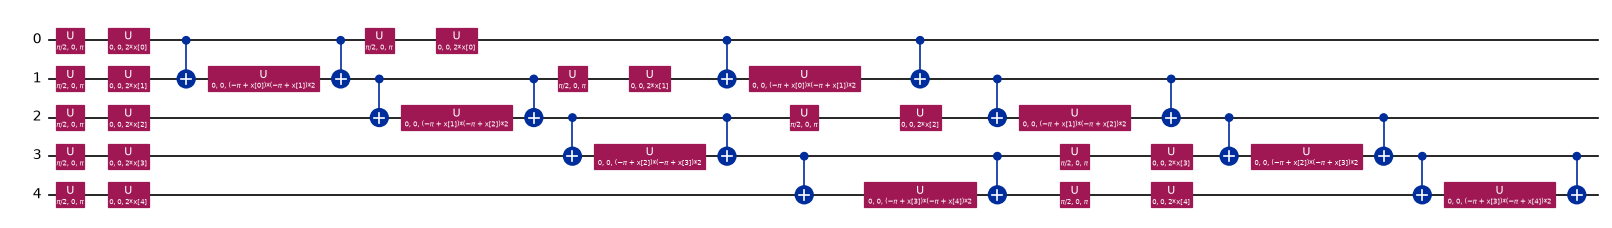

In [11]:
def zz_map(n):
    # paper: ZZFeatureMap with linear entanglement. CHOICE: reps = 2 (Qiskit default). For one qubit (ablation) there is
    # nothing to entangle, so the plain Z feature map is used.
    return zz_feature_map(n, reps=2, entanglement="linear") if n > 1 else z_feature_map(1, reps=2)

def states_circuit(fm, A):
    # state vectors by simulating the Qiskit circuit, one input row at a time (slow in pure Python, but it is the real circuit)
    return np.array([Statevector(fm.assign_parameters(list(a))).data for a in A])

def states(A, reps=2):
    # The same states in closed form, for many rows at once. The ZZ feature map is [diagonal phases after a Hadamard layer] x reps:
    #   phase(x, z) = sum_i 2 x_i z_i + sum_i 2 (pi - x_i)(pi - x_{i+1}) (z_i xor z_{i+1})      (linear entanglement)
    # so  |phi(x)> = D(x) H D(x) H |0...0>  with H the n-qubit Hadamard layer. Checked against the circuit in the next cell.
    A = np.asarray(A, float); m, n = A.shape; N = 2 ** n
    z = ((np.arange(N)[:, None] >> np.arange(n)) & 1).astype(float)
    H = np.ones((1, 1))
    for _ in range(n):
        H = np.kron(H, np.array([[1.0, 1.0], [1.0, -1.0]]) / np.sqrt(2))
    ph = 2 * A @ z.T
    for i in range(n - 1):
        ph += 2 * ((np.pi - A[:, i]) * (np.pi - A[:, i + 1]))[:, None] * np.abs(z[:, i] - z[:, i + 1])[None, :]
    D = np.exp(1j * ph); psi = np.zeros((m, N), complex); psi[:, 0] = 1.0
    for _ in range(reps):
        psi = D * (psi @ H.T)
    return psi

def gram(Sa, Sb):
    # fidelity kernel K_ij = |<phi(a_i)|phi(b_j)>|^2 (paper Eq. 9) from the state vectors
    return np.abs(Sa.conj() @ Sb.T) ** 2

fm_demo = zz_map(N_QUBITS)
print("ZZFeatureMap on", N_QUBITS, "qubits:", fm_demo.num_parameters, "input parameters, depth after decomposition", fm_demo.decompose().decompose().depth())
fm_demo.decompose().draw("mpl", fold=-1, scale=0.6)

closed-form states == simulated circuit states: True (max |diff| 1.4e-15)


hand-made vs FidelityStatevectorKernel   max |diff| = 4.440892098500626e-15 | np.allclose: True
hand-made vs FidelityQuantumKernel       max |diff| = 8.783286598035289e-13 (1.2 s for 10 points; one circuit per pair, so it grows with n^2)
kernel diagonal (a state overlaps itself fully): [1. 1. 1. 1.] ... ; symmetric: True


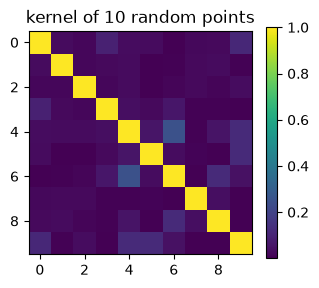

In [12]:
# Three ways of getting the same number: (a) our own Gram matrix from state vectors, (b) FidelityStatevectorKernel
# (exact, used for the experiments), (c) FidelityQuantumKernel, the class the paper names (sampler based, circuit per pair).
Xd = np.random.default_rng(SEED).uniform(0, np.pi, size=(10, N_QUBITS))
Sd = states_circuit(fm_demo, Xd)
print("closed-form states == simulated circuit states:", np.allclose(states(Xd), Sd, atol=1e-10), "(max |diff| %.1e)" % np.abs(states(Xd) - Sd).max())
K_hand = gram(Sd, Sd)
K_sv = FidelityStatevectorKernel(feature_map=fm_demo).evaluate(Xd)
t0 = time.time(); K_fq = FidelityQuantumKernel(feature_map=fm_demo).evaluate(Xd); t_fq = time.time() - t0
print("hand-made vs FidelityStatevectorKernel   max |diff| =", np.abs(K_hand - K_sv).max(), "| np.allclose:", np.allclose(K_hand, K_sv, atol=1e-8))
print("hand-made vs FidelityQuantumKernel       max |diff| =", np.abs(K_hand - K_fq).max(), f"({t_fq:.1f} s for 10 points; one circuit per pair, so it grows with n^2)")
print("kernel diagonal (a state overlaps itself fully):", np.diag(K_sv).round(6)[:4], "... ; symmetric:", np.allclose(K_sv, K_sv.T))
plt.figure(figsize=(3.6, 3)); plt.imshow(K_sv, cmap="viridis"); plt.colorbar(); plt.title("kernel of 10 random points"); plt.show()

In [13]:
def tune_qsvm(S_tr, ytr, groups, seed):
    # CHOICE: bandwidth (angle range) and SVC C are tuned on a validation part of the TRAINING rows only
    itr, iva = val_split(ytr, groups, seed)
    best = None
    for bw in BANDWIDTHS:
        A_t, A_v = to_angles(S_tr[itr], S_tr[iva], bw)
        St, Sv = states(A_t), states(A_v); Kt, Kv = gram(St, St), gram(Sv, St)     # closed-form states: fast enough to scan the grid
        for C in QSVM_C_GRID:
            acc = balanced_accuracy_score(ytr[iva], SVC(kernel="precomputed", C=C).fit(Kt, ytr[itr]).predict(Kv))
            if best is None or acc > best[0] + 1e-12:
                best = (acc, bw, C)
    return best[1], best[2], best[0]

def run_qsvm(ctx, variants=("CK", "PK", "FUNC")):
    S_tr, S_te, ytr = ctx["S_tr"], ctx["S_te"], ctx["ytr"]
    bw, C, val = tune_qsvm(S_tr, ytr, ctx["groups"], ctx["seed"])
    A_tr, A_te = to_angles(S_tr, S_te, bw); fm = zz_map(S_tr.shape[1]); out = []
    note = f"bandwidth {bw}, C {C}, validation bal.acc {val:.3f}"
    if "CK" in variants:       # SVC with the quantum kernel as a callable
        k = FidelityStatevectorKernel(feature_map=fm)
        t0 = time.perf_counter(); m = SVC(kernel=k.evaluate, C=C).fit(A_tr, ytr); t1 = time.perf_counter(); p = m.predict(A_te)
        out.append(("QSVM CK", p, dict(train_s=t1 - t0, test_s=time.perf_counter() - t1, note=note)))
    if "FUNC" in variants:     # QSVC, the quantum-kernel SVC class of qiskit-machine-learning
        k = FidelityStatevectorKernel(feature_map=fm)
        t0 = time.perf_counter(); m = QSVC(quantum_kernel=k, C=C).fit(A_tr, ytr); t1 = time.perf_counter(); p = m.predict(A_te)
        out.append(("QSVC Func", p, dict(train_s=t1 - t0, test_s=time.perf_counter() - t1, note=note)))
    if "PK" in variants:       # SVC on a precomputed kernel matrix
        k = FidelityStatevectorKernel(feature_map=fm)
        t0 = time.perf_counter(); Ktr = k.evaluate(A_tr); m = SVC(kernel="precomputed", C=C).fit(Ktr, ytr); t1 = time.perf_counter()
        p = m.predict(k.evaluate(A_te, A_tr)); out.append(("QSVM PK", p, dict(train_s=t1 - t0, test_s=time.perf_counter() - t1, note=note)))
    return out
print("quantum-kernel models defined")

quantum-kernel models defined


## 8. The quantum convolutional network (QCNN)

The QCNN follows the Qiskit tutorial: a `ZFeatureMap` loads the features, a *convolution* layer applies a trainable two-qubit
block to neighbouring qubit pairs, a *pooling* layer pushes the information of some qubits onto others, and the expectation value of
`Z` on the last remaining qubit is the network output (in [-1, 1]); the sign gives the class. The paper uses two convolution and
two pooling layers but does not give the circuit for its five qubits; the wiring below is our choice. COBYLA tunes the 27 weights to
minimise a squared-error loss. The exact Aer estimator replaces the paper's (unspecified) estimator; with `default_precision=0` there is
no sampling noise.

QCNN trainable weights: 27 (conv1 12 + pool1 6 + conv2 6 + pool2 3)


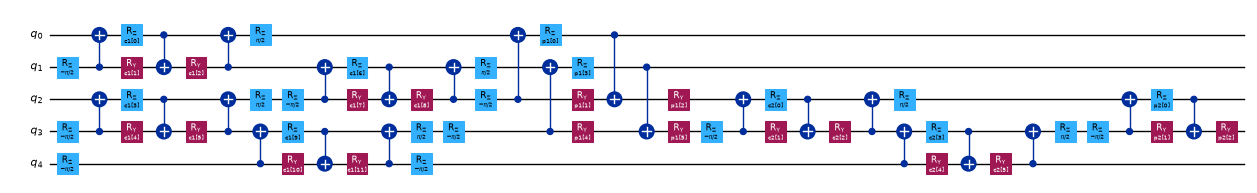

In [14]:
# QCNN after the Qiskit tutorial: ZFeatureMap -> conv -> pool -> conv -> pool -> <Z> read-out (paper: 2 conv + 2 pool layers,
# EstimatorQNN + NeuralNetworkClassifier + COBYLA). The paper does not give the wiring for its 5 qubits; CHOICE below.
def two_qubit_block(qc, p, a, b, pool=False):
    qc.rz(-np.pi / 2, b); qc.cx(b, a); qc.rz(p[0], a); qc.ry(p[1], b); qc.cx(a, b); qc.ry(p[2], b)
    if not pool:
        qc.cx(b, a); qc.rz(np.pi / 2, a)

def add_conv(qc, qubits, prefix):      # nearest-neighbour pairs: even bonds first, then odd bonds; 3 parameters per pair
    pairs = [(qubits[i], qubits[i + 1]) for i in range(0, len(qubits) - 1, 2)] + [(qubits[i], qubits[i + 1]) for i in range(1, len(qubits) - 1, 2)]
    ps = ParameterVector(prefix, 3 * len(pairs))
    for j, (a, b) in enumerate(pairs):
        two_qubit_block(qc, ps[3 * j:3 * j + 3], a, b)
    return list(ps)

def add_pool(qc, sources, sinks, prefix):   # information of the source qubits is pushed onto the sink qubits
    ps = ParameterVector(prefix, 3 * len(sources))
    for j, (s, t) in enumerate(zip(sources, sinks)):
        two_qubit_block(qc, ps[3 * j:3 * j + 3], s, t, pool=True)
    return list(ps)

def build_qcnn(n=N_QUBITS):
    fm = z_feature_map(n)                                  # paper: ZFeatureMap (reps = 2 by default)
    ans = QuantumCircuit(n); w = []
    w += add_conv(ans, [0, 1, 2, 3, 4], "c1")              # conv layer 1 on all 5 qubits   (12 weights)
    w += add_pool(ans, [0, 1], [2, 3], "p1")               # pool layer 1: qubits 0,1 -> 2,3 ( 6 weights)
    w += add_conv(ans, [2, 3, 4], "c2")                    # conv layer 2 on qubits 2,3,4   ( 6 weights)
    w += add_pool(ans, [2], [3], "p2")                     # pool layer 2: qubit 2 -> 3     ( 3 weights)
    full = QuantumCircuit(n); full.compose(fm, inplace=True); full.compose(ans, inplace=True)
    obs = SparsePauliOp.from_list([("IZIII", 1)])          # CHOICE: Pauli-Z expectation on qubit 3 (the last pooling sink)
    est = (AerEstimator(options=dict(backend_options=dict(method="statevector", seed_simulator=SEED), default_precision=0.0))
           if HAVE_AER else StatevectorEstimator())
    qnn = EstimatorQNN(circuit=full, observables=obs, input_params=list(fm.parameters), weight_params=w,
                       estimator=est, default_precision=0.0)   # default_precision=0: exact expectation values, no sampling noise
    return qnn, ans, fm

qcnn_demo, ans_demo, _ = build_qcnn()
print("QCNN trainable weights:", qcnn_demo.num_weights, "(conv1 12 + pool1 6 + conv2 6 + pool2 3)")
ans_demo.draw("mpl", fold=40, scale=0.5)

In [15]:
def run_qcnn(ctx):
    seed = ctx["seed"]; algorithm_globals.random_seed = seed
    qnn, _, _ = build_qcnn(ctx["P_tr"].shape[1]); hist = []
    clf = NeuralNetworkClassifier(qnn, optimizer=COBYLA(maxiter=QCNN_MAXITER), callback=lambda w, l: hist.append(float(l)),
                                  initial_point=algorithm_globals.random.random(qnn.num_weights))
    t0 = time.perf_counter(); clf.fit(ctx["P_tr"], 2 * ctx["ytr"] - 1); t1 = time.perf_counter()   # labels -1 / +1 (bad = +1)
    pred = (clf.predict(ctx["P_te"]).ravel() > 0).astype(int); t2 = time.perf_counter()
    return [("QCNN", pred, dict(train_s=t1 - t0, test_s=t2 - t1, loss=hist, note=f"{len(hist)} loss evaluations"))]
print("QCNN runner defined")

QCNN runner defined


## 9. Running all experiments

For every seed the notebook draws a new 5000-row subset and runs each model on the paper-order data sets (UNDER, OVER 1/17,
OVER full, OVER 1/9) and on the clean-order data sets (UNDER, OVER 1/17). Each model gets the same rows and the same
preprocessing. The paper's names are kept for the seven model rows. CNN and QCNN, the slow ones, run for the first `HEAVY_SEEDS`
seeds only. Every print line shows accuracy, recall of the malicious class and training time.

In [16]:
HEAVY = {"CNN", "QCNN"}
MODELS_ON = {
    "UNDER":     ["SVM linear", "SVM rbf", "CNN", "QSVM CK", "QSVC Func", "QSVM PK", "QCNN", "RandomForest (quantum inputs)", "SVC rbf (quantum inputs)"],
    "OVER 1/17": ["SVM linear", "SVM rbf", "CNN", "QSVM CK", "QSVC Func", "QSVM PK", "QCNN", "RandomForest (quantum inputs)", "SVC rbf (quantum inputs)"],
    "OVER full": ["SVM rbf", "CNN", "RandomForest (quantum inputs)", "SVC rbf (quantum inputs)"],
    "OVER 1/9":  ["SVM linear"]}
# CHOICE: the whole oversampled set (7800 training rows) is expensive for the SVM grid search and the CNN, so it is run for the
# heavy-model seeds only, and not at all in FAST_MODE (the 1/17 and 1/9 subsets then stand in for it in the tables).
PROTOCOL_DATASETS = {"paper": ["UNDER", "OVER 1/17"] + ([] if FAST_MODE else ["OVER full"]) + ["OVER 1/9"], "clean": ["UNDER", "OVER 1/17"]}

def metrics(yt, yp):
    return dict(acc=100 * accuracy_score(yt, yp), prec=100 * precision_score(yt, yp, zero_division=0),
                rec=100 * recall_score(yt, yp, zero_division=0), f1=100 * f1_score(yt, yp, zero_division=0),
                bacc=100 * balanced_accuracy_score(yt, yp))

def make_ctx(X, y, tr, te, seed, features=PAPER_FEATURES if USE_PAPER_FEATURES else None):
    prep = Prep(features).fit(X.iloc[tr], y[tr])
    S_tr, S_te = prep.transform(X.iloc[tr]), prep.transform(X.iloc[te])
    P_tr, P_te = to_angles(S_tr, S_te, 1.0)
    return dict(S_tr=S_tr, S_te=S_te, P_tr=P_tr, P_te=P_te, ytr=y[tr], yte=y[te], groups=tr, seed=seed, cols=prep.cols)

def dispatch(model, ctx):
    if model == "SVM linear": return run_svm("linear", ctx)
    if model == "SVM rbf": return run_svm("rbf", ctx)
    if model == "CNN": return run_cnn(ctx)
    if model == "QCNN": return run_qcnn(ctx)
    if model == "RandomForest (quantum inputs)": return run_rf(ctx)
    if model == "SVC rbf (quantum inputs)": return run_svc_pi(ctx)
    raise KeyError(model)

print("run definitions ready; datasets per protocol:", PROTOCOL_DATASETS)

run definitions ready; datasets per protocol: {'paper': ['UNDER', 'OVER 1/17', 'OVER full', 'OVER 1/9'], 'clean': ['UNDER', 'OVER 1/17']}


In [17]:
ROWS, STORE, HISTORY = [], {}, {}
T_START = time.time()

for seed in SEEDS:
    X, y, _ = draw_sample(pool, seed)
    for proto, dnames in PROTOCOL_DATASETS.items():
        for dname in dnames:
            if dname == "OVER full" and seed not in SEEDS[:HEAVY_SEEDS]:
                continue
            if FAST_MODE and proto == "clean" and seed not in SEEDS[:HEAVY_SEEDS]:
                continue                         # FAST_MODE: the clean protocol only for the first seed
            regime, frac = DATASETS[dname]
            tr, te = build_split(y, regime, frac, proto, seed)
            ctx = make_ctx(X, y, tr, te, seed)
            leak = 100 * np.isin(te, tr).mean()
            todo = [m for m in MODELS_ON[dname] if not (m in HEAVY and seed not in SEEDS[:HEAVY_SEEDS])]
            qnames = {"QSVM CK", "QSVC Func", "QSVM PK"}
            jobs = [m for m in todo if m not in qnames] + (["QSVM (3 variants)"] if qnames & set(todo) else [])
            for model in jobs:
                # the three QSVM variants are one model (checked below), so the clean protocol, whose natural test set has 1000 rows, runs only PK
                outs = (run_qsvm(ctx, variants=("PK",) if proto == "clean" else ("CK", "PK", "FUNC")) if model.startswith("QSVM") else dispatch(model, ctx))
                for name, pred, info in outs:
                    ROWS.append(dict(seed=seed, protocol=proto, dataset=dname, model=name, n_train=len(tr), n_test=len(te),
                                     test_overlap_pct=leak, **metrics(ctx["yte"], pred), train_s=info["train_s"], test_s=info["test_s"], note=info.get("note", "")))
                    if seed == SEEDS[0]:
                        STORE[(proto, dname, name)] = (ctx["yte"], pred, te)
                        if "history" in info or "loss" in info:
                            HISTORY[(proto, dname, name)] = info.get("history", info.get("loss"))
                    print(f"seed {seed} | {proto:5s} | {dname:9s} | {name:30s} | acc {ROWS[-1]['acc']:6.2f} | recall {ROWS[-1]['rec']:6.2f} | "
                          f"train {info['train_s']:7.1f} s | elapsed {(time.time()-T_START)/60:5.1f} min", flush=True)

res = pd.DataFrame(ROWS)
print(f"\nfinished {len(res)} model runs in {(time.time()-T_START)/60:.1f} minutes")

seed 42 | paper | UNDER     | SVM linear                     | acc  93.48 | recall  86.96 | train     0.5 s | elapsed   0.0 min


seed 42 | paper | UNDER     | SVM rbf                        | acc  93.48 | recall  86.96 | train     1.2 s | elapsed   0.0 min


seed 42 | paper | UNDER     | CNN                            | acc  93.48 | recall  86.96 | train    31.0 s | elapsed   0.6 min


seed 42 | paper | UNDER     | QCNN                           | acc  91.30 | recall  82.61 | train    38.9 s | elapsed   1.2 min


seed 42 | paper | UNDER     | RandomForest (quantum inputs)  | acc  97.83 | recall  95.65 | train     0.8 s | elapsed   1.2 min


...

seed 46 | clean | OVER 1/17 | SVM rbf                        | acc  96.80 | recall 100.00 | train     1.4 s | elapsed  27.9 min


seed 46 | clean | OVER 1/17 | RandomForest (quantum inputs)  | acc  98.50 | recall 100.00 | train     0.6 s | elapsed  27.9 min


seed 46 | clean | OVER 1/17 | SVC rbf (quantum inputs)       | acc  96.80 | recall 100.00 | train     0.0 s | elapsed  27.9 min


seed 46 | clean | OVER 1/17 | QSVM PK                        | acc  98.20 | recall 100.00 | train     8.5 s | elapsed  28.3 min



finished 149 model runs in 28.3 minutes


## 10. The paper's Tables 4, 5 and 6 recomputed

Accuracy, precision, recall and F1 of the **malicious** class in %, mean +- std over the seeds, test sets of the paper's order
(46 rows for UNDER, 115 for OVER 1/17, about 1950 for OVER full, about 1090 for OVER 1/9, with `n_test` printed). `train_s` / `test_s`
are wall-clock seconds on this machine (paper Table 6). The last two rows are the baselines on the quantum inputs.

In [18]:
def fmt(s):
    return f"{s.mean():.2f} +- {s.std(ddof=0):.2f}" if len(s) > 1 else f"{s.iloc[0]:.2f}"

PAPER_MODELS = ["QSVM CK", "SVM linear", "QSVC Func", "SVM rbf", "QSVM PK", "QCNN", "CNN"]    # order of the paper's tables
PAPER_VIEW = {"UNDER": {m: "UNDER" for m in PAPER_MODELS},
              "OVER": {"SVM linear": "OVER 1/9", "SVM rbf": "OVER full", "CNN": "OVER full",
                       "QSVM CK": "OVER 1/17", "QSVC Func": "OVER 1/17", "QSVM PK": "OVER 1/17", "QCNN": "OVER 1/17"}}

def view_ds(regime, model, protocol="paper"):
    # the data set the paper used for this model; falls back to OVER 1/17 where the larger one was not run (FAST_MODE)
    ds = PAPER_VIEW[regime].get(model, "UNDER" if regime == "UNDER" else "OVER 1/17")
    return ds if ((res.protocol == protocol) & (res.dataset == ds) & (res.model == model)).any() else "OVER 1/17"

def paper_table(res, protocol, regime, models=PAPER_MODELS, extra=()):
    out = []
    for m in list(models) + list(extra):
        ds = view_ds(regime, m, protocol)
        r = res[(res.protocol == protocol) & (res.dataset == ds) & (res.model == m)]
        if len(r) == 0:
            continue
        out.append(dict(model=m, data=ds, runs=len(r), n_test=int(r.n_test.iloc[0]), **{k: fmt(r[k]) for k in ["acc", "prec", "rec", "f1"]},
                        train_s=f"{r.train_s.mean():.1f}", test_s=f"{r.test_s.mean():.2f}"))
    return pd.DataFrame(out)

EXTRA = ["RandomForest (quantum inputs)", "SVC rbf (quantum inputs)"]
for regime in ["UNDER", "OVER"]:
    print(f"=== this notebook, paper order (resample, then split), {regime}sampled data: mean +- std over seeds, % (cf. paper Table {'4' if regime=='UNDER' else '5'}) ===")
    display(paper_table(res, "paper", regime, extra=EXTRA).set_index("model"))

=== this notebook, paper order (resample, then split), UNDERsampled data: mean +- std over seeds, % (cf. paper Table 4) ===


,data,runs,n_test,acc,prec,rec,f1,train_s,test_s
model,,,,,,,,,
QSVM CK,UNDER,5,46,97.39 +- 2.54,98.40 +- 3.20,96.52 +- 5.07,97.33 +- 2.66,1.7,1.70
SVM linear,UNDER,5,46,95.65 +- 3.64,98.26 +- 3.48,93.04 +- 5.90,95.47 +- 3.75,0.5,0.00
QSVC Func,UNDER,5,46,97.39 +- 2.54,98.40 +- 3.20,96.52 +- 5.07,97.33 +- 2.66,1.6,1.48
SVM rbf,UNDER,5,46,96.52 +- 2.95,100.00 +- 0.00,93.04 +- 5.90,96.30 +- 3.15,1.0,0.00
QSVM PK,UNDER,5,46,97.39 +- 2.54,98.40 +- 3.20,96.52 +- 5.07,97.33 +- 2.66,1.8,1.97
QCNN,UNDER,2,46,89.13 +- 2.17,100.00 +- 0.00,78.26 +- 4.35,87.74 +- 2.74,38.5,0.06
CNN,UNDER,2,46,93.48 +- 0.00,100.00 +- 0.00,86.96 +- 0.00,93.02 +- 0.00,29.0,0.53
RandomForest (quantum inputs),UNDER,5,46,99.13 +- 1.06,100.00 +- 0.00,98.26 +- 2.13,99.11 +- 1.09,0.7,0.05
SVC rbf (quantum inputs),UNDER,5,46,97.83 +- 1.94,98.40 +- 3.20,97.39 +- 3.48,97.81 +- 1.95,0.0,0.00


=== this notebook, paper order (resample, then split), OVERsampled data: mean +- std over seeds, % (cf. paper Table 5) ===


,data,runs,n_test,acc,prec,rec,f1,train_s,test_s
model,,,,,,,,,
QSVM CK,OVER 1/17,5,115,96.87 +- 2.50,97.24 +- 2.82,96.50 +- 3.14,96.84 +- 2.52,5.9,2.84
SVM linear,OVER 1/9,5,218,97.06 +- 1.25,96.99 +- 2.67,97.25 +- 1.64,97.08 +- 1.21,2.8,0.00
QSVC Func,OVER 1/17,5,115,96.87 +- 2.50,97.24 +- 2.82,96.50 +- 3.14,96.84 +- 2.52,5.5,3.98
SVM rbf,OVER full,2,1955,97.57 +- 1.20,98.69 +- 1.31,96.42 +- 1.13,97.54 +- 1.21,172.4,0.33
QSVM PK,OVER 1/17,5,115,96.87 +- 2.50,97.24 +- 2.82,96.50 +- 3.14,96.84 +- 2.52,6.2,3.52
QCNN,OVER 1/17,2,115,90.87 +- 3.04,100.00 +- 0.00,81.58 +- 6.14,89.73 +- 3.73,128.2,0.16
CNN,OVER full,2,1955,99.36 +- 0.13,99.19 +- 0.70,99.54 +- 0.46,99.36 +- 0.12,41.4,0.75
RandomForest (quantum inputs),OVER 1/17,5,115,99.48 +- 0.70,99.33 +- 1.33,99.65 +- 0.70,99.48 +- 0.68,0.8,0.05
SVC rbf (quantum inputs),OVER 1/17,5,115,96.52 +- 2.13,96.23 +- 2.54,96.86 +- 2.33,96.53 +- 2.14,0.0,0.00


## 11. Confusion matrices and training curves (paper Figs 12-22)

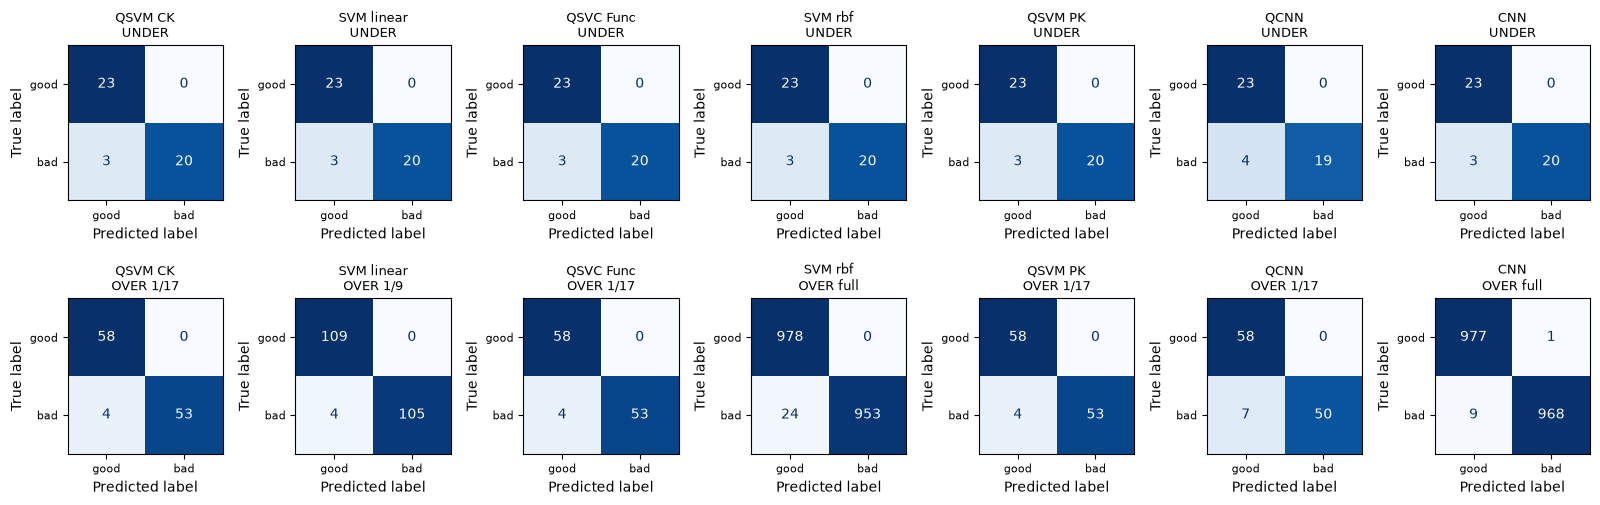

In [19]:
# Confusion matrices of the first seed (paper Figs 12-18, 21); rows = truth, columns = prediction, malicious ('bad') = positive.
fig, axes = plt.subplots(2, len(PAPER_MODELS), figsize=(2.3 * len(PAPER_MODELS), 5.2))
for i, regime in enumerate(["UNDER", "OVER"]):
    for j, m in enumerate(PAPER_MODELS):
        ds = view_ds(regime, m); ax = axes[i, j]
        if ("paper", ds, m) in STORE:
            yt, yp, _ = STORE[("paper", ds, m)]
            ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=[0, 1]), display_labels=["good", "bad"]).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{m}\n{ds}", fontsize=9); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

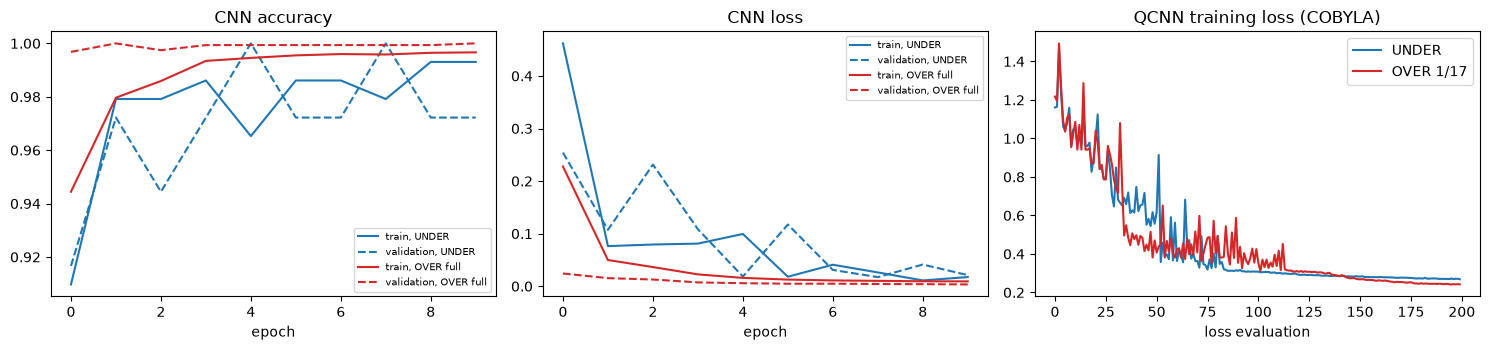

In [20]:
# Training curves: CNN accuracy / loss (paper Fig. 19) and QCNN loss (paper Fig. 22), first heavy seed.
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for ds, c in [("UNDER", "tab:blue"), (view_ds("OVER", "CNN"), "tab:red")]:
    h = HISTORY.get(("paper", ds, "CNN"))
    if h:
        ax[0].plot(h["accuracy"], c=c, label=f"train, {ds}"); ax[0].plot(h["val_accuracy"], "--", c=c, label=f"validation, {ds}")
        ax[1].plot(h["loss"], c=c, label=f"train, {ds}"); ax[1].plot(h["val_loss"], "--", c=c, label=f"validation, {ds}")
ax[0].set_title("CNN accuracy"); ax[1].set_title("CNN loss"); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
for ds, c in [("UNDER", "tab:blue"), ("OVER 1/17", "tab:red")]:
    h = HISTORY.get(("paper", ds, "QCNN"))
    if h:
        ax[2].plot(h, c=c, label=ds)
ax[2].set_title("QCNN training loss (COBYLA)"); ax[2].set_xlabel("loss evaluation"); ax[2].legend()
plt.tight_layout(); plt.show()

## 12. The order of resampling and splitting: paper order vs clean order

If oversampled copies end up on both sides of the split, accuracy measures memory, not generalisation. The table compares, per
model, the paper-order accuracy with the clean-order results on the natural test set (about 2.3 % malicious). Note that the clean
numbers use a very different test set, so they cannot be compared one-to-one in accuracy; precision / recall / F1 of the malicious
class and the balanced accuracy are the meaningful columns.

In [21]:
# Where does the oversampling-before-splitting order matter? Compare the paper's order with the clean order
# (split first, resample only the training part, test on the natural class ratio) for the same seeds.
def mean_by(res, **kw):
    r = res
    for k, v in kw.items():
        r = r[r[k] == v]
    return r

cmp_rows = []
for dname in ["UNDER", "OVER 1/17"]:
    for m in PAPER_MODELS + EXTRA:
        a = mean_by(res, protocol="paper", dataset=dname, model=m); b = mean_by(res, protocol="clean", dataset=dname, model=m)
        if len(a) and len(b):
            cmp_rows.append(dict(dataset=dname, model=m, paper_order_acc=a.acc.mean(), paper_order_overlap_pct=a.test_overlap_pct.mean(),
                                 clean_acc=b.acc.mean(), clean_bal_acc=b.bacc.mean(), clean_recall_bad=b.rec.mean(), clean_precision_bad=b.prec.mean(), clean_f1_bad=b.f1.mean()))
leak_df = pd.DataFrame(cmp_rows).round(2)
display(leak_df)
print("Reading guide: 'paper_order_overlap_pct' = share of the test rows that also sit in the training set (0 for undersampling).")
print("The clean columns are measured on the natural class ratio (about 2.3 % malicious), so precision and F1 of the malicious class are the honest numbers there;")
print("plain accuracy is flattered by the benign majority.")

,dataset,model,paper_order_acc,paper_order_overlap_pct,clean_acc,clean_bal_acc,clean_recall_bad,clean_precision_bad,clean_f1_bad
0,UNDER,SVM linear,95.65,0.00,98.12,95.64,93.04,67.26,74.54
1,UNDER,SVM rbf,96.52,0.00,98.38,95.77,93.04,73.99,78.78
2,UNDER,QSVM PK,97.39,0.00,96.84,95.41,93.91,45.81,59.77
3,UNDER,QCNN,89.13,0.00,99.25,83.70,67.39,100.00,80.50
4,UNDER,CNN,93.48,0.00,98.95,94.16,89.13,77.78,81.63
5,UNDER,RandomForest (quantum inputs),99.13,0.00,98.76,97.67,96.52,73.09,81.16
6,UNDER,SVC rbf (quantum inputs),97.83,0.00,97.12,95.98,94.78,51.69,63.73
7,OVER 1/17,SVM linear,96.52,42.43,96.76,95.37,93.91,42.09,57.68
8,OVER 1/17,SVM rbf,96.52,42.43,96.96,95.90,94.78,50.27,62.38
9,OVER 1/17,QSVM PK,96.87,42.43,98.76,96.39,93.91,67.41,78.09


Reading guide: 'paper_order_overlap_pct' = share of the test rows that also sit in the training set (0 for undersampling).
The clean columns are measured on the natural class ratio (about 2.3 % malicious), so precision and F1 of the malicious class are the honest numbers there;
plain accuracy is flattered by the benign majority.


## 13. Why is the task so easy? The role of `js_len` and `js_obf_len`

The paper reports 100 % for the QSVM and calls it "unexpected". Four cells look at the data instead of the model:

1. hand-written rules (no learning) applied to the 100,000 pages, and a decision tree with a single split;
2. the pages that the models get wrong - are they the same pages for every model?
3. the best score any classifier could reach with these five features (an oracle that knows the class mix of every feature pattern);
4. an ablation that removes feature groups and re-trains three models.

If a single threshold on a JavaScript length already gets close to the best model's accuracy, the dataset, not the quantum kernel,
explains the result.

In [22]:
# How much of the task is the JavaScript length alone? Hand-written rules without any learning, on the natural pool (100,000 pages).
bad_p = pool["label"] == "bad"
rules = {
  "js_obf_len > 0":                          pool.js_obf_len > 0,
  "js_len > 199.5":                          pool.js_len > 199.5,
  "js_len > 199.5  or  js_obf_len > 0":      (pool.js_len > 199.5) | (pool.js_obf_len > 0),
  "...  or  (who_is incomplete and no https)": (pool.js_len > 199.5) | (pool.js_obf_len > 0) | ((pool.who_is == "incomplete") & (pool.https == "no")),
}
rr = []
for name, r in rules.items():
    tp = int((r & bad_p).sum()); fp = int((r & ~bad_p).sum()); fn = int((~r & bad_p).sum())
    rr.append(dict(rule=name, accuracy=100 * (r == bad_p).mean(), precision=100 * tp / max(tp + fp, 1), recall=100 * tp / (tp + fn), false_positives=fp, missed_malicious=fn))
display(pd.DataFrame(rr).round(2).set_index("rule"))
print(f"malicious pages with NO JavaScript at all (js_len = 0): {int(((pool.js_len==0) & bad_p).sum())} of {int(bad_p.sum())} -> these are only recognisable from who_is / https / tld")

# a depth-1 decision tree (a single threshold on one feature) on the natural 5000-row sample, split 80/20
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X0, y0, test_size=TEST_SIZE, stratify=y0, random_state=SEED)
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(Xn_tr, yn_tr)
print("\ndecision stump, learned from data:\n" + export_text(stump, feature_names=ALL_COLS))
print(f"stump test accuracy {100*accuracy_score(yn_te, stump.predict(Xn_te)):.2f} %, malicious recall {100*recall_score(yn_te, stump.predict(Xn_te)):.1f} %, precision {100*precision_score(yn_te, stump.predict(Xn_te)):.1f} %")

,accuracy,precision,recall,false_positives,missed_malicious
rule,,,,,
js_obf_len > 0,99.74,100.00,88.54,0,258
js_len > 199.5,99.87,100.00,94.18,0,131
js_len > 199.5 or js_obf_len > 0,99.87,100.00,94.18,0,131
... or (who_is incomplete and no https),96.12,36.62,98.76,3848,28


malicious pages with NO JavaScript at all (js_len = 0): 131 of 2251 -> these are only recognisable from who_is / https / tld

decision stump, learned from data:
|--- js_len <= 263.10
|   |--- class: 0
|--- js_len >  263.10
|   |--- class: 1



stump test accuracy 99.80 %, malicious recall 91.3 %, precision 100.0 %


In [23]:
# Which pages do the models get wrong? Seed-42 undersampled test set (46 pages), paper order. If different models fail on the SAME
# pages, those pages are not separable with these features and the model family is not the limit.
names = ["SVM linear", "SVM rbf", "QSVM PK", "RandomForest (quantum inputs)", "SVC rbf (quantum inputs)"]
wrong = {}
for m in names:
    yt, yp, te_idx = STORE[("paper", "UNDER", m)]; wrong[m] = set(te_idx[yt != yp].tolist())
all_wrong = set.intersection(*wrong.values()); any_wrong = set.union(*wrong.values())
print(f"pages missed by at least one of the {len(names)} models: {len(any_wrong)}; missed by all of them: {len(all_wrong)}   (test set: 46 pages, 23 malicious)")
tbl = sample0.loc[sorted(any_wrong), ["url", "tld", "who_is", "https", "js_len", "js_obf_len", "label"]].copy()
tbl["url"] = tbl["url"].str.slice(0, 45)
for m in names:
    tbl[m] = ["wrong" if i in wrong[m] else "" for i in tbl.index]
display(tbl)

pages missed by at least one of the 5 models: 3; missed by all of them: 1   (test set: 46 pages, 23 malicious)


,url,tld,who_is,https,js_len,js_obf_len,label,SVM linear,SVM rbf,QSVM PK,RandomForest (quantum inputs),SVC rbf (quantum inputs)
2646,http://www.amateur-porn-movies.net/,net,incomplete,no,326.7,0.0,bad,wrong,wrong,wrong,,
4277,http://xyzbluebook.org/satinsheetsluts/,org,incomplete,no,320.4,0.0,bad,wrong,wrong,wrong,,wrong
4473,http://kalibertina.over-blog.com/,com,complete,no,0.0,0.0,bad,wrong,wrong,wrong,wrong,wrong


In [24]:
# How good can ANY classifier be with these five features? Discretise them into the 15 patterns that actually occur and let an
# oracle that knows the class mix of every pattern (measured on the 100,000 pages) decide; this is the Bayes-optimal balanced accuracy
# of the discretised features. It is a property of the DATA, not a model, so it is safe to measure on the whole pool.
pat = pd.DataFrame({"js_len>199.5": pool.js_len > 199.5, "js_len=0": pool.js_len == 0, "js_obf_len>0": pool.js_obf_len > 0, "who_is": pool.who_is, "https": pool.https})
key = pat.astype(str).agg("|".join, axis=1)
ct = pd.crosstab(key, bad_p)
fb, fg = ct[True] / ct[True].sum(), ct[False] / ct[False].sum()
ceiling = 0.5 * np.maximum(fb, fg).sum()
print(f"{len(ct)} patterns occur; oracle balanced accuracy = {100*ceiling:.2f} %   (tld adds almost nothing: it is a country-code mix)")
print(f"expected errors of this oracle on a 46-row balanced test set: {46*(1-ceiling):.2f};  P(0 errors) = {100*ceiling**46:.0f} %")
n_nojs = int(((pool.js_len == 0) & bad_p).sum())
print(f"malicious pages without any JavaScript: {n_nojs} of {int(bad_p.sum())} ({100*n_nojs/bad_p.sum():.1f} %); P(a test set of 23 malicious pages contains none) = {100*(1-n_nojs/bad_p.sum())**23:.0f} %")
print("=> a perfect score on a 46-row test set is an ordinary outcome for any model that learned the JavaScript rule; a miss or two is equally ordinary.")

15 patterns occur; oracle balanced accuracy = 99.28 %   (tld adds almost nothing: it is a country-code mix)
expected errors of this oracle on a 46-row balanced test set: 0.33;  P(0 errors) = 72 %
malicious pages without any JavaScript: 131 of 2251 (5.8 %); P(a test set of 23 malicious pages contains none) = 25 %
=> a perfect score on a 46-row test set is an ordinary outcome for any model that learned the JavaScript rule; a miss or two is equally ordinary.


In [25]:
# Ablation: which features carry the separation? Same protocol as the paper's undersampled experiment, five feature sets,
# three cheap models on identical inputs (RBF-SVC and random forest on the angles, the quantum kernel machine with tuned bandwidth).
FEATURE_SETS = {
    "all five (paper)":                  PAPER_FEATURES,
    "without js_obf_len":                ["tld", "who_is", "https", "js_len"],
    "without both JavaScript features":  ["tld", "who_is", "https"],
    "js_len and js_obf_len only":        ["js_len", "js_obf_len"],
    "js_obf_len only":                   ["js_obf_len"],
    "js_len only":                       ["js_len"]}
abl = []
for seed in SEEDS:
    Xs, ys, _ = draw_sample(pool, seed); tr, te = build_split(ys, "under", 1, "paper", seed)
    for fname, feats in FEATURE_SETS.items():
        ctx = make_ctx(Xs, ys, tr, te, seed, features=feats)
        for name, pred, info in run_rf(ctx) + run_svc_pi(ctx) + run_qsvm(ctx, variants=("PK",)):
            abl.append(dict(features=fname, n_qubits=len(feats), model=name.replace(" (quantum inputs)", " (same inputs)"), seed=seed, acc=100 * accuracy_score(ctx["yte"], pred)))
abl = pd.DataFrame(abl)
tab = abl.pivot_table(index=["features", "n_qubits"], columns="model", values="acc", aggfunc=lambda s: f"{s.mean():.1f} +- {s.std(ddof=0):.1f}")
tab = tab.loc[[(k, len(v)) for k, v in FEATURE_SETS.items()]]
print("test accuracy % on the undersampled data, mean +- std over", len(SEEDS), "seeds (about 46 test rows per seed):")
display(tab)

test accuracy % on the undersampled data, mean +- std over 5 seeds (about 46 test rows per seed):


,model,QSVM PK,RandomForest (same inputs),SVC rbf (same inputs)
features,n_qubits,,,
all five (paper),5,97.4 +- 2.5,99.1 +- 1.1,97.8 +- 1.9
without js_obf_len,4,96.1 +- 3.7,99.1 +- 1.1,97.0 +- 2.2
without both JavaScript features,3,87.0 +- 3.6,86.5 +- 3.2,87.0 +- 3.6
js_len and js_obf_len only,2,95.2 +- 2.9,97.4 +- 2.5,96.1 +- 3.5
js_obf_len only,1,93.0 +- 2.1,93.0 +- 2.1,93.0 +- 2.1
js_len only,1,96.5 +- 3.3,97.4 +- 2.5,97.4 +- 2.5


## 14. This notebook against the paper

The verdict rule is the factory's: **reproduced** if our mean is within 2 points of the paper's value, otherwise *exceeded* or
*not reached* by the gap. With a single test set of 46 rows one error is worth 2.2 points, so the paper's own numbers are only
as precise as that; our means over several seeds average over different subsets.

In [26]:
# The paper's tables 4, 5 and 6 (accuracy, precision, recall, F1 in %, and training / testing time in s)
PAPER = {
 "UNDER": {"QSVM CK": (100.00, 100.00, 100.00, 100.00), "SVM linear": (97.83, 100.00, 96.15, 98.04), "QSVC Func": (100.00, 100.00, 100.00, 100.00),
           "SVM rbf": (93.48, 100.00, 88.46, 93.88), "QSVM PK": (100.00, 100.00, 100.00, 100.00), "QCNN": (84.78, 82.14, 92.00, 86.79), "CNN": (91.30, 95.83, 88.46, 92.00)},
 "OVER":  {"QSVM CK": (100.00, 100.00, 100.00, 100.00), "SVM linear": (97.49, 98.60, 96.21, 97.39), "QSVC Func": (100.00, 100.00, 100.00, 100.00),
           "SVM rbf": (99.95, 100.00, 99.89, 99.95), "QSVM PK": (100.00, 100.00, 100.00, 100.00), "QCNN": (85.22, 79.69, 92.73, 85.71), "CNN": (99.90, 100.00, 99.79, 99.89)}}
PAPER_TIME = {  # model: (train UNDER, test UNDER, train OVER, test OVER)  -- Table 6
 "QSVM CK": (138.60, 82.70, 1053.40, 505.99), "SVM linear": (35.30, 0.01, 224.70, 0.03), "QSVC Func": (156.30, 75.84, 1150.70, 572.35),
 "SVM rbf": (2.70, 0.05, 17.70, 0.04), "QSVM PK": (221.30, 0.01, 1541.80, 0.01), "QCNN": (244.80, 0.30, 589.94, 1.30), "CNN": (3.00, 14.60, 6.70, 17.60)}
print("paper tables stored")

paper tables stored


In [27]:
# Side-by-side with the paper. Verdict rule (AGENT_BRIEF): "reproduced" if within 2 points, otherwise "exceeded" / "not reached" by the gap.
def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

claims = []
for regime in ["UNDER", "OVER"]:
    for m in PAPER_MODELS:
        ds = view_ds(regime, m); r = res[(res.protocol == "paper") & (res.dataset == ds) & (res.model == m)]
        if len(r) == 0:
            continue
        pa, pp, pr, pf = PAPER[regime][m]
        claims.append(dict(claim=f"{m}, {regime.lower()}sampled", n_runs=len(r), paper_acc=pa, ours_acc=round(r.acc.mean(), 2), verdict_acc=verdict(r.acc.mean(), pa),
                           paper_f1=pf, ours_f1=round(r.f1.mean(), 2), verdict_f1=verdict(r.f1.mean(), pf)))
claims = pd.DataFrame(claims)
display(claims)

def macc(regime, model, protocol="paper"):
    return res[(res.protocol == protocol) & (res.dataset == view_ds(regime, model, protocol)) & (res.model == model)].acc.mean()

def seed_acc(regime, model, protocol="paper"):
    r = res[(res.protocol == protocol) & (res.dataset == view_ds(regime, model, protocol)) & (res.model == model)]
    return r.set_index("seed").acc

def paired(regime, a_models, b_models, protocol="paper"):
    # per-seed accuracy difference (best of a_models minus best of b_models), seeds that both sides share
    a = pd.concat([seed_acc(regime, m, protocol) for m in a_models], axis=1).max(axis=1)
    b = pd.concat([seed_acc(regime, m, protocol) for m in b_models], axis=1).max(axis=1)
    d = (a - b).dropna(); return d

qual = []
for regime in ["UNDER", "OVER"]:
    d = paired(regime, ["QSVM CK", "QSVC Func", "QSVM PK"], ["SVM linear", "SVM rbf"])
    qual.append((f"QSVM outperforms the best SVM ({regime.lower()}sampled)",
                 f"QSVM minus best SVM, per seed: {', '.join(f'{v:+.1f}' for v in d)} (mean {d.mean():+.2f} points)",
                 "reproduced" if (d.min() > 0 and d.mean() > 1.0) else ("not reached (SVM better)" if d.mean() < -1.0 else "not reached (no consistent gap; within seed noise)")))
    d = paired(regime, ["CNN"], ["QCNN"])
    qual.append((f"CNN outperforms QCNN ({regime.lower()}sampled)", f"CNN minus QCNN, per seed: {', '.join(f'{v:+.1f}' for v in d)} (mean {d.mean():+.2f} points; heavy seeds only)",
                 "reproduced" if (d.min() > 0 and d.mean() > 1.0) else ("not reached (QCNN better)" if d.mean() < -1.0 else "not reached (no consistent gap)")))
d = paired("UNDER", ["RandomForest (quantum inputs)", "SVC rbf (quantum inputs)"], ["QSVM CK", "QSVC Func", "QSVM PK"])
qual.append(("(not in the paper) is the QSVM better than a random forest / plain RBF-SVC on the same inputs? undersampled", f"best classical baseline minus QSVM, per seed: {', '.join(f'{v:+.1f}' for v in d)}",
             "no: the baseline is at least as good" if d.mean() >= 0 else "yes"))
allm = [m for m in PAPER_MODELS]
u_mean = np.nanmean([macc("UNDER", m) for m in allm]); o_mean = np.nanmean([macc("OVER", m) for m in allm])
cf = res[(res.protocol == "clean") & res.model.isin(PAPER_MODELS + EXTRA)].groupby("dataset").f1.mean()
paper_order_yes = o_mean > u_mean + 1.0
clean_yes = ("OVER 1/17" in cf.index and "UNDER" in cf.index and cf["OVER 1/17"] > cf["UNDER"] + 1.0)
qual.append(("oversampling gives better results than undersampling (mean accuracy over the 7 models)",
             f"paper order: accuracy over {o_mean:.2f} vs under {u_mean:.2f};  clean order: F1 of the malicious class over {cf.get('OVER 1/17', np.nan):.1f} vs under {cf.get('UNDER', np.nan):.1f}",
             ("reproduced in the paper's order and in the clean order" if (paper_order_yes and clean_yes) else
              "reproduced in the paper's order only (the clean order shows no clear advantage)" if paper_order_yes else "not reached")))
tq = res[(res.protocol == "paper") & (res.dataset == "UNDER")].groupby("model")[["train_s", "test_s"]].mean()
ratio = (tq.loc[["QSVM CK", "QSVC Func", "QSVM PK"], "train_s"].mean() / tq.loc["SVM rbf", "train_s"])
qual.append(("quantum models are slower than classical ones (paper: QSVM 50-80x the RBF-SVM's training time on undersampled data)",
             f"QSVM {tq.loc[['QSVM CK','QSVC Func','QSVM PK'],'train_s'].mean():.1f} s vs SVM rbf {tq.loc['SVM rbf','train_s']:.1f} s (x{ratio:.0f}); QCNN {tq.loc['QCNN','train_s']:.0f} s vs CNN {tq.loc['CNN','train_s']:.0f} s",
             "reproduced (direction; absolute times depend on machine and simulator)" if ratio > 1 else "not reached"))
qual.append(("Table 6 absolute times", "different machine, simulator and kernel implementation", "cannot be checked"))
qual.append(("QSVM CK, PK and QSVC Func are three separate confirmations of 100 %", "same kernel, same SVC, same predictions in every run (check below)", "not independent: one result counted three times"))
pd.set_option("display.max_colwidth", 140)
display(pd.DataFrame(qual, columns=["qualitative claim", "this notebook", "verdict"]))

same = []
for (seed, proto, ds), g in res[res.model.isin(["QSVM CK", "QSVM PK", "QSVC Func"]) & (res.protocol == "paper")].groupby(["seed", "protocol", "dataset"]):
    key = lambda m: tuple(np.round(g[g.model == m][["acc", "prec", "rec"]].iloc[0].values, 9))
    same.append(dict(seed=seed, dataset=ds, identical=(key("QSVM CK") == key("QSVM PK") == key("QSVC Func"))))
same = pd.DataFrame(same)
print("QSVM CK, PK and QSVC Func give identical accuracy / precision / recall in all runs:", bool(same.identical.all()), f"({len(same)} runs compared)")

,claim,n_runs,paper_acc,ours_acc,verdict_acc,paper_f1,ours_f1,verdict_f1
0,"QSVM CK, undersampled",5,100.00,97.39,not reached (-2.6),100.00,97.33,not reached (-2.7)
1,"SVM linear, undersampled",5,97.83,95.65,not reached (-2.2),98.04,95.47,not reached (-2.6)
2,"QSVC Func, undersampled",5,100.00,97.39,not reached (-2.6),100.00,97.33,not reached (-2.7)
3,"SVM rbf, undersampled",5,93.48,96.52,exceeded (+3.0),93.88,96.30,exceeded (+2.4)
4,"QSVM PK, undersampled",5,100.00,97.39,not reached (-2.6),100.00,97.33,not reached (-2.7)
5,"QCNN, undersampled",2,84.78,89.13,exceeded (+4.4),86.79,87.74,reproduced
6,"CNN, undersampled",2,91.30,93.48,exceeded (+2.2),92.00,93.02,reproduced
7,"QSVM CK, oversampled",5,100.00,96.87,not reached (-3.1),100.00,96.84,not reached (-3.2)
8,"SVM linear, oversampled",5,97.49,97.06,reproduced,97.39,97.08,reproduced
9,"QSVC Func, oversampled",5,100.00,96.87,not reached (-3.1),100.00,96.84,not reached (-3.2)


,qualitative claim,this notebook,verdict
0,QSVM outperforms the best SVM (undersampled),"QSVM minus best SVM, per seed: +0.0, +4.3, +0.0, +0.0, +0.0 (mean +0.87 points)",not reached (no consistent gap; within seed noise)
1,CNN outperforms QCNN (undersampled),"CNN minus QCNN, per seed: +2.2, +6.5 (mean +4.35 points; heavy seeds only)",reproduced
2,QSVM outperforms the best SVM (oversampled),"QSVM minus best SVM, per seed: -2.3, -3.3, +2.8, +3.7, -3.0 (mean -0.42 points)",not reached (no consistent gap; within seed noise)
3,CNN outperforms QCNN (oversampled),"CNN minus QCNN, per seed: +5.6, +11.4 (mean +8.49 points; heavy seeds only)",reproduced
4,(not in the paper) is the QSVM better than a random forest / plain RBF-SVC on the same inputs? undersampled,"best classical baseline minus QSVM, per seed: +4.3, +0.0, +0.0, +4.3, +0.0",no: the baseline is at least as good
5,oversampling gives better results than undersampling (mean accuracy over the 7 models),paper order: accuracy over 96.50 vs under 95.28; clean order: F1 of the malicious class over 71.0 vs under 72.9,reproduced in the paper's order only (the clean order shows no clear advantage)
6,quantum models are slower than classical ones (paper: QSVM 50-80x the RBF-SVM's training time on undersampled data),QSVM 1.7 s vs SVM rbf 1.0 s (x2); QCNN 39 s vs CNN 29 s,reproduced (direction; absolute times depend on machine and simulator)
7,Table 6 absolute times,"different machine, simulator and kernel implementation",cannot be checked
8,"QSVM CK, PK and QSVC Func are three separate confirmations of 100 %","same kernel, same SVC, same predictions in every run (check below)",not independent: one result counted three times


QSVM CK, PK and QSVC Func give identical accuracy / precision / recall in all runs: True (10 runs compared)


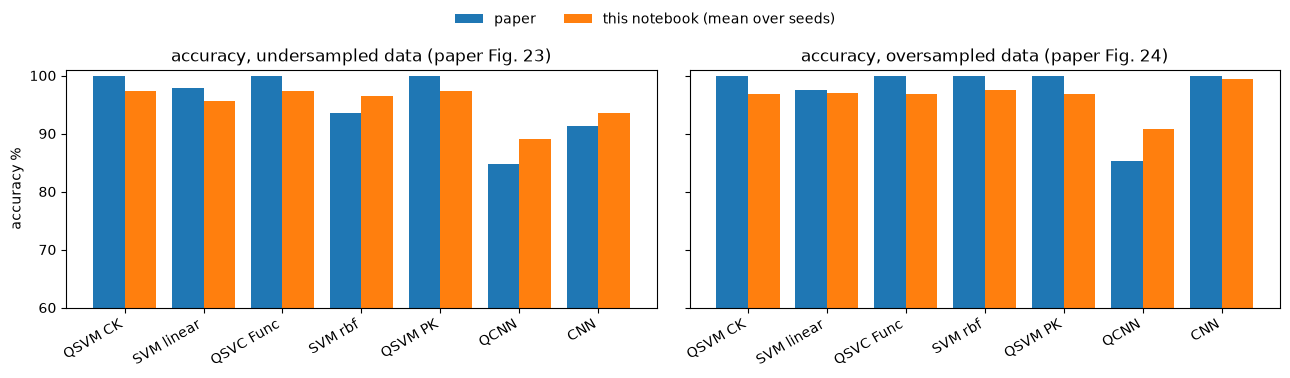

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, regime in zip(axes, ["UNDER", "OVER"]):
    x = np.arange(len(PAPER_MODELS)); ours = [macc(regime, m) for m in PAPER_MODELS]
    ax.bar(x - 0.2, [PAPER[regime][m][0] for m in PAPER_MODELS], 0.4, label="paper"); ax.bar(x + 0.2, ours, 0.4, label="this notebook (mean over seeds)")
    ax.set_xticks(x); ax.set_xticklabels(PAPER_MODELS, rotation=30, ha="right"); ax.set_ylim(60, 101); ax.set_title(f"accuracy, {regime.lower()}sampled data (paper Fig. {'23' if regime=='UNDER' else '24'})")
axes[0].set_ylabel("accuracy %")
h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

## 15. Reading the paper critically


All numbers below are from the cells above (full run, five seeds unless stated; CNN and QCNN two seeds).

**1. The data nearly separate themselves.** In the 100,000 pages used here no benign page has obfuscated JavaScript (0 of 97,749),
and no benign page has more than 199.5 units of JavaScript, while 94.2 % of the malicious pages are above that line. A rule with no
learning at all, `js_len > 199.5`, scores 99.87 % accuracy with no false positive and 94.2 % recall (Section 13); the one-split decision
tree learns the same kind of rule. `js_obf_len` is a part of `js_len` (for malicious pages that contain JavaScript its share never
exceeds 0.94 and averages 0.63) that is exactly zero for every benign page, so it behaves like a label: ANOVA ranks it first
(F about 23,000, against 6,600 for `js_len` and 350 for the third feature), and its correlation with the label is 0.91. Whatever
process produced the two columns, benign and malicious pages occupy disjoint ranges of them, so almost any classifier that sees them is near the
ceiling. The ablation agrees: `js_len` alone gives about 97 % for the random forest and the RBF-SVC and 96.5 % for the QSVM;
without both JavaScript columns every model falls to about 87 %.

**2. A 46-row test set cannot rank models that differ by one to four errors.** The best any classifier can do with these five features
(Bayes-optimal balanced accuracy of their 15 value patterns) is 99.3 %, so an oracle that knows each pattern's class mix scores 100 % on a
random 46-row balanced test set about 72 % of the time. A perfect score on one such split is therefore an ordinary event, not an "unexpected" one. One miss costs 2.2 points, so
the paper's Table 4 spread (100, 97.83, 93.48, 91.30) is zero to four errors on one split of one random subset, without a seed or an interval.
Over five random subsets the same models score 97.4 +- 2.5 % (QSVM), 95.7 +- 3.6 % (linear SVM) and 96.5 +- 3.0 % (RBF-SVM): the means
overlap within one standard deviation, and the QSVM equals the best SVM on four of the five subsets and beats it on one.

**3. Every model misses the same pages.** In the seed-42 test set three malicious pages are missed by the linear SVM, the RBF-SVM and the
QSVM alike: two have a large `js_len` (about 320) without obfuscated JavaScript, one has no JavaScript at all. The random forest,
which can put a threshold on `js_len` alone, finds two of the three. The limit is the smooth, kernel-shaped decision surface meeting a
rule-shaped data set, not "classical against quantum".

**4. Oversampling before splitting inflates the oversampled results.** In the paper's order 42 % of the test rows of the 1/17 subset
(50 % of the whole oversampled set) are exact copies of training rows. Models that can memorise gain from it (random forest, whole-set
RBF-SVM and CNN all reach 97.5-99.5 %), and the paper's finding that oversampling beats undersampling, against the textbook expectation it
cites, is what this leak produces. In the clean order (split first, test on the natural 2.3 % malicious ratio) oversampling shows no clear
advantage (see the comparison table in Section 14) and the honest numbers are much lower: the malicious-class F1 of the kernel
machines is between 58 and 87 % (QSVM 60 % / 78 %, RBF-SVM 79 % / 62 %, random forest 81 % / 87 % for undersampled / oversampled training),
because a false-positive rate of a few per cent on the 97.7 % benign pages swamps the 2.3 % malicious ones. For comparison, the hand-written
`js_len > 199.5` rule has precision 100 %, recall 94 % and F1 97 % on the 100,000 natural pages (a threshold read off the same pages, so optimistic),
and the one-split tree learned on 80 % of a natural 5000-row subset reaches precision 100 % and recall 91 % on the held-out 20 %.

**5. QSVM CK, QSVM PK and QSVC Func are one experiment.** They use the same kernel and the same SVC, so they return the same predictions
(identical in all 10 comparisons here). The paper counts three perfect results; there is one, and it differs only in implementation time.

**6. No evidence of a quantum advantage, and the explanation offered is untested.** On identical inputs a random forest (99.1 +- 1.1 %)
and a default RBF-SVC (97.8 +- 1.9 %) match or beat the tuned QSVM (97.4 +- 2.5 %). The paper attributes the QSVM's result to a high-dimensional
entangled feature space that links `js_obf_len` and `tld`, but it runs no ablation (Exercise 4 does), and `tld` has an ANOVA F of about 4.
The paper's SVM-RBF grid has `gamma` of at most 0.001 on standardised data, which makes that kernel almost linear and the classical comparison
weaker than necessary. The quantum result also depends on a bandwidth the paper never mentions (Exercise 3). The paper's own reference [42]
(Slattery et al., 2023) reports numerical evidence *against* advantage for fidelity kernels on classical data.

**7. CNN against QCNN.** We confirm the order (CNN about 93 % / 99 %, QCNN about 89 % / 91 % on undersampled / oversampled data), but both scores depend on
choices the paper does not report: for the CNN the random-search trials, batch size and learning rate; for the 5-qubit QCNN (27 weights, a one-qubit
read-out) the wiring and the COBYLA budget. Our QCNN even scores above the paper's 85 %. "QCNNs are designed for image-like data" is a
hypothesis, not a finding.

**8. Time and hardware.** Table 6's minutes are the cost of simulating circuits on a laptop: `FidelityQuantumKernel` builds a circuit per pair of
rows. The same kernel in closed form (Section 7) takes seconds here (QSVM about 1.7 s of training against the paper's 138.6 s on undersampled data, so the 50-80x gap of Table 6 shrinks to about 2x), and no simulator time says
anything about hardware, where noise, not run time, would be the issue (not studied; Exercise 5).

**9. Reporting gaps.** No seeds, no code, no statement of which data the scaler, the ANOVA selector and the capping were fitted on (the
natural reading is the whole subset before splitting, which leaks); a PCA of five features into five components "capturing 100 % of the variance" says nothing;
the 1/9 and 1/17 data fractions appear only in the limitations section; the data are described as available on request although the dataset is public.

**Bottom line.** Reproduced: the linear SVM and CNN on the oversampled set, the ordering CNN > QCNN, and slow quantum simulation. Not reproduced: 100 % for the QSVM
(we get 97.4 +- 2.5 % and 96.9 +- 2.5 %), "QSVM beats SVM" (a tie within noise), and "oversampling beats undersampling" (an artefact of the split order).
What the experiment really shows is that this data set is solved by a threshold on one JavaScript length; it cannot discriminate between quantum and classical models.


## 16. Exercises

1. **Shuffle test.** Permute the training labels (keep the test labels) in the undersampled experiment and re-run the QSVM and the
   random forest. Chance level is 50 %; if a model scores clearly above it, something other than the labels carries information.
2. **A genuinely URL-based model.** The `url` column holds the real address string. Build character n-gram or lexical features
   (length, number of dots, digits, suspicious words such as `login`) and repeat the comparison *without* `js_len` and `js_obf_len`.
   How much of the 100 % survives, and does the quantum kernel still match the RBF-SVM?
3. **Bandwidth sweep.** Set `BANDWIDTHS = [1.0]` and `QSVM_C_GRID = [1.0]` (no tuning) and compare with the tuned numbers. How much
   of the QSVM's score depends on a hyper-parameter the paper never mentions?
4. **Entanglement and depth.** Change `zz_map` to `entanglement="full"` or `reps=1`, or replace the ZZ map by the product-state `z_feature_map`
   (no entanglement at all). Does the kernel result move? What does that say about the "entanglement captures hidden relationships" argument?
5. **Noise.** Replace the exact kernel by a sampler-based `FidelityQuantumKernel` with a noisy `qiskit_ibm_runtime.fake_provider` backend
   and watch the 5-qubit kernel degrade with the number of shots; set `IBM_TOKEN` to run on real hardware if you have access.